In [ ]:
# =====================================================
# STEP 1: INSTALL PACKAGES, MOUNT DRIVE, IMPORTS
# =====================================================

!pip -q install timm grad-cam statsmodels openpyxl fvcore

from google.colab import drive
drive.mount("/content/drive")

import os
import gc
import copy
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode

import timm

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

from statsmodels.stats.contingency_tables import mcnemar

warnings.filterwarnings("ignore")


# =====================================================
# EXPERIMENTAL CONFIGURATION
# =====================================================

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 30
LEARNING_RATE = 1e-4
N_FOLDS = 5
NUM_WORKERS = 2
THRESHOLD = 0.5

# New cleaned dataset path
DATASET_DIR = Path(
    "/content/drive/MyDrive/Brishty_ml/"
    "clean_dataset_brishty/images"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Brishty_ml/"
    "reviewer_final_results"
)

MODEL_DIR = OUTPUT_DIR / "saved_models"
FIGURE_DIR = OUTPUT_DIR / "figures"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "encroachment_present",
    "no_encroachment"
]

CLASS_TO_IDX = {
    "encroachment_present": 0,
    "no_encroachment": 1
}

IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

print("Device:", DEVICE)
print("Dataset path:", DATASET_DIR)
print("Output path:", OUTPUT_DIR)
print("Dataset folder exists:", DATASET_DIR.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Dataset path: /content/drive/MyDrive/Brishty_ml/clean_dataset_brishty/images
Output path: /content/drive/MyDrive/Brishty_ml/reviewer_final_results
Dataset folder exists: True


In [ ]:
# =====================================================
# STEP 2: DATASET COUNT, FIXED TEST SET,
#         AND FIXED 5-FOLD ASSIGNMENT
# =====================================================

def collect_images(dataset_dir):
    image_paths = []
    labels = []

    for class_name in CLASS_NAMES:
        class_folder = dataset_dir / class_name

        if not class_folder.exists():
            raise FileNotFoundError(
                f"Class folder not found: {class_folder}"
            )

        for root, _, files in os.walk(class_folder):
            for file_name in sorted(files):

                if file_name.lower().endswith(IMAGE_EXTENSIONS):
                    image_path = str(Path(root) / file_name)

                    image_paths.append(image_path)
                    labels.append(CLASS_TO_IDX[class_name])

    return (
        np.asarray(image_paths),
        np.asarray(labels, dtype=np.int64)
    )


# -----------------------------------------------------
# 1. Read actual cleaned dataset
# -----------------------------------------------------

all_image_paths, all_labels = collect_images(DATASET_DIR)

if len(all_image_paths) == 0:
    raise RuntimeError(
        f"No images found inside: {DATASET_DIR}"
    )

print("=" * 65)
print("CLEANED DATASET SUMMARY")
print("=" * 65)

print("Total images found:", len(all_image_paths))

for class_name, class_index in CLASS_TO_IDX.items():
    class_count = int(
        np.sum(all_labels == class_index)
    )

    print(
        f"{class_name}: {class_count} images"
    )


# -----------------------------------------------------
# 2. Create fixed independent test set
# -----------------------------------------------------
# 15% = independent test set
# 85% = development set for 5-fold CV

(
    development_paths,
    test_paths,
    development_labels,
    test_labels
) = train_test_split(
    all_image_paths,
    all_labels,
    test_size=0.15,
    random_state=SEED,
    stratify=all_labels,
    shuffle=True
)


def show_distribution(split_name, labels):
    print(f"\n{split_name}: {len(labels)} images")

    for class_name, class_index in CLASS_TO_IDX.items():
        class_count = int(
            np.sum(labels == class_index)
        )

        print(
            f"  {class_name}: {class_count}"
        )


show_distribution(
    "Development set for 5-fold CV",
    development_labels
)

show_distribution(
    "Independent test set",
    test_labels
)


# -----------------------------------------------------
# 3. Assign every development image to one fixed fold
# -----------------------------------------------------
# fold_id indicates the fold in which that image
# will serve as validation data.
#
# Example:
# fold_id = 1
#   validation = fold 1 images
#   training   = folds 2, 3, 4, 5 images

development_fold_ids = np.zeros(
    len(development_paths),
    dtype=np.int64
)

skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED
)

for fold_number, (_, validation_indices) in enumerate(
    skf.split(
        development_paths,
        development_labels
    ),
    start=1
):
    development_fold_ids[
        validation_indices
    ] = fold_number


# Safety checks

if np.any(development_fold_ids == 0):
    raise RuntimeError(
        "Some development images were not assigned to a fold."
    )

if set(np.unique(development_fold_ids)) != set(
    range(1, N_FOLDS + 1)
):
    raise RuntimeError(
        "Fold assignment is incomplete."
    )


# -----------------------------------------------------
# 4. Show every fold's train/validation size
# -----------------------------------------------------

print("\n" + "=" * 65)
print("FIXED 5-FOLD DISTRIBUTION")
print("=" * 65)

for fold_number in range(1, N_FOLDS + 1):

    validation_mask = (
        development_fold_ids == fold_number
    )

    training_mask = ~validation_mask

    fold_train_labels = development_labels[
        training_mask
    ]

    fold_val_labels = development_labels[
        validation_mask
    ]

    print(f"\nFold {fold_number}")

    print(
        f"  Training images: "
        f"{len(fold_train_labels)}"
    )

    print(
        f"  Validation images: "
        f"{len(fold_val_labels)}"
    )

    for class_name, class_index in CLASS_TO_IDX.items():

        train_count = int(
            np.sum(
                fold_train_labels == class_index
            )
        )

        val_count = int(
            np.sum(
                fold_val_labels == class_index
            )
        )

        print(
            f"  {class_name} -> "
            f"Train: {train_count}, "
            f"Validation: {val_count}"
        )


# -----------------------------------------------------
# 5. Save fixed split and fold assignment
# -----------------------------------------------------

development_df = pd.DataFrame({
    "image_path": development_paths,
    "label": development_labels.astype(int),
    "class_name": [
        CLASS_NAMES[int(label)]
        for label in development_labels
    ],
    "dataset_role": "development",
    "fold_id": development_fold_ids
})

test_df = pd.DataFrame({
    "image_path": test_paths,
    "label": test_labels.astype(int),
    "class_name": [
        CLASS_NAMES[int(label)]
        for label in test_labels
    ],
    "dataset_role": "test",
    "fold_id": 0
})

fixed_split_df = pd.concat(
    [
        development_df,
        test_df
    ],
    ignore_index=True
)

fixed_split_path = (
    OUTPUT_DIR /
    "fixed_test_and_5fold_split.csv"
)

fixed_split_df.to_csv(
    fixed_split_path,
    index=False
)


# Save test set separately for easy reuse

fixed_test_path = (
    OUTPUT_DIR /
    "fixed_test_set.csv"
)

test_df.to_csv(
    fixed_test_path,
    index=False
)


# Save development folds separately

fixed_folds_path = (
    OUTPUT_DIR /
    "fixed_5fold_development_set.csv"
)

development_df.to_csv(
    fixed_folds_path,
    index=False
)


print("\n" + "=" * 65)
print("STEP 2 COMPLETED")
print("=" * 65)

print("Complete split file:")
print(fixed_split_path)

print("\nDevelopment folds file:")
print(fixed_folds_path)

print("\nIndependent test file:")
print(fixed_test_path)

print(
    "\nThese same files must be used "
    "for all five model notebooks."
)

CLEANED DATASET SUMMARY
Total images found: 7411
encroachment_present: 3891 images
no_encroachment: 3520 images

Development set for 5-fold CV: 6299 images
  encroachment_present: 3307
  no_encroachment: 2992

Independent test set: 1112 images
  encroachment_present: 584
  no_encroachment: 528

FIXED 5-FOLD DISTRIBUTION

Fold 1
  Training images: 5039
  Validation images: 1260
  encroachment_present -> Train: 2646, Validation: 661
  no_encroachment -> Train: 2393, Validation: 599

Fold 2
  Training images: 5039
  Validation images: 1260
  encroachment_present -> Train: 2646, Validation: 661
  no_encroachment -> Train: 2393, Validation: 599

Fold 3
  Training images: 5039
  Validation images: 1260
  encroachment_present -> Train: 2645, Validation: 662
  no_encroachment -> Train: 2394, Validation: 598

Fold 4
  Training images: 5039
  Validation images: 1260
  encroachment_present -> Train: 2645, Validation: 662
  no_encroachment -> Train: 2394, Validation: 598

Fold 5
  Training images:

In [ ]:
# =====================================================
# STEP 3: LOAD FIXED SPLIT, PREPROCESSING,
#         DATASET CLASS, AND DATALOADER
# =====================================================

# -----------------------------------------------------
# 1. Load the fixed split files from Step 2
# -----------------------------------------------------

FOLD_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_5fold_development_set.csv"
)

TEST_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_test_set.csv"
)

if not FOLD_CSV_PATH.exists():
    raise FileNotFoundError(
        f"Development fold CSV not found: {FOLD_CSV_PATH}"
    )

if not TEST_CSV_PATH.exists():
    raise FileNotFoundError(
        f"Test CSV not found: {TEST_CSV_PATH}"
    )

development_df = pd.read_csv(FOLD_CSV_PATH)
test_df = pd.read_csv(TEST_CSV_PATH)


# -----------------------------------------------------
# 2. Check required columns
# -----------------------------------------------------

required_columns = {
    "image_path",
    "label",
    "class_name",
    "dataset_role",
    "fold_id"
}

if not required_columns.issubset(development_df.columns):
    raise ValueError(
        "Development CSV does not contain all required columns."
    )

if not required_columns.issubset(test_df.columns):
    raise ValueError(
        "Test CSV does not contain all required columns."
    )


# -----------------------------------------------------
# 3. Verify split information
# -----------------------------------------------------

print("=" * 65)
print("LOADED FIXED SPLIT")
print("=" * 65)

print("Development images:", len(development_df))
print("Independent test images:", len(test_df))

print(
    "Available fold IDs:",
    sorted(
        development_df["fold_id"]
        .astype(int)
        .unique()
        .tolist()
    )
)

print("\nDevelopment class distribution:")

print(
    development_df["class_name"]
    .value_counts()
)

print("\nTest class distribution:")

print(
    test_df["class_name"]
    .value_counts()
)


# -----------------------------------------------------
# 4. Check whether every image path exists
# -----------------------------------------------------

development_df["file_exists"] = (
    development_df["image_path"]
    .apply(lambda path: Path(path).exists())
)

test_df["file_exists"] = (
    test_df["image_path"]
    .apply(lambda path: Path(path).exists())
)

missing_development = development_df[
    development_df["file_exists"] == False
]

missing_test = test_df[
    test_df["file_exists"] == False
]

print("\nMissing development images:", len(missing_development))
print("Missing test images:", len(missing_test))

if len(missing_development) > 0:
    print(
        missing_development[
            ["image_path", "class_name", "fold_id"]
        ].head()
    )

    raise FileNotFoundError(
        "Some development image files are missing."
    )

if len(missing_test) > 0:
    print(
        missing_test[
            ["image_path", "class_name"]
        ].head()
    )

    raise FileNotFoundError(
        "Some test image files are missing."
    )

development_df = development_df.drop(
    columns=["file_exists"]
)

test_df = test_df.drop(
    columns=["file_exists"]
)


# -----------------------------------------------------
# 5. ImageNet normalization
# -----------------------------------------------------

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


# -----------------------------------------------------
# 6. Training augmentation
# -----------------------------------------------------
# Same experimental configuration:
# - Resize: 224 × 224
# - Horizontal flip
# - Rotation: ±10 degrees
# - Zoom: ±10%
# - Brightness adjustment
# - ImageNet normalization

train_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE),
        interpolation=InterpolationMode.BILINEAR
    ),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(
        degrees=10,
        interpolation=InterpolationMode.BILINEAR
    ),

    transforms.RandomAffine(
        degrees=0,
        scale=(0.90, 1.10),
        interpolation=InterpolationMode.BILINEAR
    ),

    transforms.ColorJitter(
        brightness=0.10
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# -----------------------------------------------------
# 7. Validation and test preprocessing
# -----------------------------------------------------
# No augmentation for validation and test images.

eval_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE),
        interpolation=InterpolationMode.BILINEAR
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# -----------------------------------------------------
# 8. SEVD PyTorch Dataset
# -----------------------------------------------------

class SEVDDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):
        self.dataframe = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = row["image_path"]
        label = float(row["label"])

        try:
            image = Image.open(
                image_path
            ).convert("RGB")

        except Exception as error:
            raise RuntimeError(
                f"Could not read image: {image_path}"
            ) from error

        if self.transform is not None:
            image = self.transform(image)

        label_tensor = torch.tensor(
            label,
            dtype=torch.float32
        )

        return {
            "image": image,
            "label": label_tensor,
            "image_path": image_path
        }


# -----------------------------------------------------
# 9. DataLoader creator
# -----------------------------------------------------

def create_dataloader(
    dataframe,
    transform,
    shuffle
):

    dataset = SEVDDataset(
        dataframe=dataframe,
        transform=transform
    )

    dataloader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=(NUM_WORKERS > 0)
    )

    return dataset, dataloader


# -----------------------------------------------------
# 10. Create fixed test DataLoader
# -----------------------------------------------------

test_dataset, test_loader = create_dataloader(
    dataframe=test_df,
    transform=eval_transform,
    shuffle=False
)


# -----------------------------------------------------
# 11. Check one fold manually
# -----------------------------------------------------

CHECK_FOLD = 1

fold_train_df = development_df[
    development_df["fold_id"] != CHECK_FOLD
].reset_index(drop=True)

fold_val_df = development_df[
    development_df["fold_id"] == CHECK_FOLD
].reset_index(drop=True)

fold_train_dataset, fold_train_loader = create_dataloader(
    dataframe=fold_train_df,
    transform=train_transform,
    shuffle=True
)

fold_val_dataset, fold_val_loader = create_dataloader(
    dataframe=fold_val_df,
    transform=eval_transform,
    shuffle=False
)


# -----------------------------------------------------
# 12. Load one sample batch
# -----------------------------------------------------

sample_batch = next(
    iter(fold_train_loader)
)

print("\n" + "=" * 65)
print("DATALOADER CHECK")
print("=" * 65)

print("Checked fold:", CHECK_FOLD)
print("Fold training images:", len(fold_train_dataset))
print("Fold validation images:", len(fold_val_dataset))
print("Test images:", len(test_dataset))

print(
    "Image batch shape:",
    sample_batch["image"].shape
)

print(
    "Label batch shape:",
    sample_batch["label"].shape
)

print(
    "First five labels:",
    sample_batch["label"][:5].tolist()
)

print(
    "Training batches:",
    len(fold_train_loader)
)

print(
    "Validation batches:",
    len(fold_val_loader)
)

print(
    "Test batches:",
    len(test_loader)
)

print("\nStep 3 completed successfully.")

LOADED FIXED SPLIT
Development images: 6299
Independent test images: 1112
Available fold IDs: [1, 2, 3, 4, 5]

Development class distribution:
class_name
encroachment_present    3307
no_encroachment         2992
Name: count, dtype: int64

Test class distribution:
class_name
encroachment_present    584
no_encroachment         528
Name: count, dtype: int64

Missing development images: 0
Missing test images: 0

DATALOADER CHECK
Checked fold: 1
Fold training images: 5039
Fold validation images: 1260
Test images: 1112
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First five labels: [0.0, 0.0, 1.0, 1.0, 1.0]
Training batches: 158
Validation batches: 40
Test batches: 35

Step 3 completed successfully.


In [ ]:
# =====================================================
# STEP 4: BUILD EfficientNetB0 MODEL
#         USING THE ORIGINAL CODE SETTINGS
# =====================================================

import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import (
    preprocess_input as efficientnet_preprocess
)


# =====================================================
# 1. Clear previous TensorFlow session
# =====================================================

tf.keras.backend.clear_session()

tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)


# =====================================================
# 2. Original model builder
# =====================================================

def build_efficientnetb0_model():

    # ImageNet-pretrained EfficientNetB0 backbone
    base_model = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(
            IMG_SIZE,
            IMG_SIZE,
            3
        )
    )

    # Same as previous Code 3:
    # freeze the complete pretrained backbone
    base_model.trainable = False

    inputs = layers.Input(
        shape=(
            IMG_SIZE,
            IMG_SIZE,
            3
        ),
        name="input_image"
    )

    # -------------------------------------------------
    # Same augmentation used in previous Code 3
    # -------------------------------------------------

    x = layers.RandomFlip(
        mode="horizontal",
        seed=SEED,
        name="random_horizontal_flip"
    )(inputs)

    x = layers.RandomRotation(
        factor=0.1,
        seed=SEED,
        name="random_rotation"
    )(x)

    x = layers.RandomZoom(
        height_factor=0.1,
        width_factor=0.1,
        seed=SEED,
        name="random_zoom"
    )(x)

    # -------------------------------------------------
    # EfficientNet-specific preprocessing
    # -------------------------------------------------

    x = efficientnet_preprocess(
        x
    )

    # -------------------------------------------------
    # Frozen feature extractor
    # -------------------------------------------------

    x = base_model(
        x,
        training=False
    )

    # -------------------------------------------------
    # Same classification head as previous Code 3
    # -------------------------------------------------

    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    x = layers.Dropout(
        rate=0.4,
        name="dropout_0_4"
    )(x)

    outputs = layers.Dense(
        units=1,
        activation="sigmoid",
        name="binary_output"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name="SEVD_EfficientNetB0"
    )

    # -------------------------------------------------
    # Same optimizer, learning rate and loss
    # -------------------------------------------------

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),

        loss="binary_crossentropy",

        metrics=[
            tf.keras.metrics.BinaryAccuracy(
                name="accuracy"
            ),

            tf.keras.metrics.Precision(
                name="precision"
            ),

            tf.keras.metrics.Recall(
                name="recall"
            ),

            # Reviewer-required AUC
            tf.keras.metrics.AUC(
                name="auc"
            )
        ]
    )

    return model, base_model


# =====================================================
# 3. Build model
# =====================================================

model_b0, base_model_b0 = (
    build_efficientnetb0_model()
)


# =====================================================
# 4. Parameter verification
# =====================================================

total_parameters = model_b0.count_params()

trainable_parameters = int(
    np.sum([
        tf.keras.backend.count_params(weight)
        for weight in model_b0.trainable_weights
    ])
)

frozen_parameters = (
    total_parameters -
    trainable_parameters
)


print("=" * 70)
print("EfficientNetB0 MODEL CONFIGURATION")
print("=" * 70)

print("Model name:", model_b0.name)
print("Input size:", (IMG_SIZE, IMG_SIZE, 3))
print("Backbone:", base_model_b0.name)
print("Backbone trainable:", base_model_b0.trainable)
print("Dropout rate:", 0.4)
print("Output activation:", "sigmoid")
print("Optimizer:", "Adam")
print("Learning rate:", LEARNING_RATE)
print("Loss:", "binary_crossentropy")
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)

print("\nTotal parameters:", f"{total_parameters:,}")
print(
    "Trainable parameters:",
    f"{trainable_parameters:,}"
)
print(
    "Frozen parameters:",
    f"{frozen_parameters:,}"
)


# =====================================================
# 5. Safety checks
# =====================================================

assert base_model_b0.trainable is False, (
    "EfficientNetB0 backbone is not frozen."
)

assert model_b0.output_shape == (None, 1), (
    "Binary output shape is incorrect."
)

assert isinstance(
    model_b0.optimizer,
    tf.keras.optimizers.Adam
), "Optimizer is not Adam."


print("\nModel summary:\n")

model_b0.summary()

print(
    "\nStep 4 completed successfully."
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 MODEL CONFIGURATION
Model name: SEVD_EfficientNetB0
Input size: (224, 224, 3)
Backbone: efficientnetb0
Backbone trainable: False
Dropout rate: 0.4
Output activation: sigmoid
Optimizer: Adam
Learning rate: 0.0001
Loss: binary_crossentropy
Epochs: 30
Batch size: 32

Total parameters: 4,050,852
Trainable parameters: 1,281
Frozen parameters: 4,049,571

Model summary:



Model: "SEVD_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_horizontal_flip          │ (None, 224, 224, 3)    │             0 │
│ (RandomFlip)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_0_4 (Dropout)           │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ binary_output (Dense)           │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Step 4 completed successfully.


In [ ]:
# =====================================================
# STEP 5: CREATE TENSORFLOW DATA PIPELINE
#         FOR FIXED 5-FOLD CROSS-VALIDATION
# =====================================================

# -----------------------------------------------------
# 1. Reload fixed CSV files
# -----------------------------------------------------

FOLD_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_5fold_development_set.csv"
)

TEST_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_test_set.csv"
)

development_df = pd.read_csv(
    FOLD_CSV_PATH
)

test_df = pd.read_csv(
    TEST_CSV_PATH
)

development_df["fold_id"] = (
    development_df["fold_id"]
    .astype(int)
)

development_df["label"] = (
    development_df["label"]
    .astype(np.float32)
)

test_df["label"] = (
    test_df["label"]
    .astype(np.float32)
)


# -----------------------------------------------------
# 2. TensorFlow image loading function
# -----------------------------------------------------

def load_and_prepare_image(
    image_path,
    label
):

    image_bytes = tf.io.read_file(
        image_path
    )

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([
        None,
        None,
        3
    ])

    image = tf.image.resize(
        image,
        size=[
            IMG_SIZE,
            IMG_SIZE
        ],
        method="bilinear"
    )

    image = tf.cast(
        image,
        tf.float32
    )

    label = tf.cast(
        label,
        tf.float32
    )

    return image, label


# -----------------------------------------------------
# 3. TensorFlow dataset creator
# -----------------------------------------------------
# Augmentation is already inside the EfficientNetB0 model.
# Therefore, this pipeline only loads and resizes images.

def create_tf_dataset(
    dataframe,
    training=False
):

    image_paths = dataframe[
        "image_path"
    ].astype(str).values

    labels = dataframe[
        "label"
    ].astype(np.float32).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            image_paths,
            labels
        )
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_and_prepare_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False
    )

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


# -----------------------------------------------------
# 4. Create fixed test dataset
# -----------------------------------------------------

test_tf_dataset = create_tf_dataset(
    dataframe=test_df,
    training=False
)


# -----------------------------------------------------
# 5. Prepare Fold 1 for verification
# -----------------------------------------------------

CHECK_FOLD = 1

fold_train_df = development_df[
    development_df["fold_id"] != CHECK_FOLD
].reset_index(
    drop=True
)

fold_val_df = development_df[
    development_df["fold_id"] == CHECK_FOLD
].reset_index(
    drop=True
)

fold_train_tf_dataset = create_tf_dataset(
    dataframe=fold_train_df,
    training=True
)

fold_val_tf_dataset = create_tf_dataset(
    dataframe=fold_val_df,
    training=False
)


# -----------------------------------------------------
# 6. Check one batch
# -----------------------------------------------------

sample_images, sample_labels = next(
    iter(fold_train_tf_dataset)
)

print("=" * 70)
print("TENSORFLOW DATASET CHECK")
print("=" * 70)

print("Checked fold:", CHECK_FOLD)

print(
    "Fold training images:",
    len(fold_train_df)
)

print(
    "Fold validation images:",
    len(fold_val_df)
)

print(
    "Independent test images:",
    len(test_df)
)

print(
    "Training batches:",
    tf.data.experimental.cardinality(
        fold_train_tf_dataset
    ).numpy()
)

print(
    "Validation batches:",
    tf.data.experimental.cardinality(
        fold_val_tf_dataset
    ).numpy()
)

print(
    "Test batches:",
    tf.data.experimental.cardinality(
        test_tf_dataset
    ).numpy()
)

print(
    "Image batch shape:",
    sample_images.shape
)

print(
    "Label batch shape:",
    sample_labels.shape
)

print(
    "Image dtype:",
    sample_images.dtype
)

print(
    "Label dtype:",
    sample_labels.dtype
)

print(
    "First five labels:",
    sample_labels[:5].numpy().tolist()
)

print(
    "Minimum pixel value:",
    float(
        tf.reduce_min(
            sample_images
        ).numpy()
    )
)

print(
    "Maximum pixel value:",
    float(
        tf.reduce_max(
            sample_images
        ).numpy()
    )
)


# -----------------------------------------------------
# 7. Final safety checks
# -----------------------------------------------------

assert sample_images.shape[1:] == (
    IMG_SIZE,
    IMG_SIZE,
    3
), "Image shape is incorrect."

assert sample_labels.shape[0] <= BATCH_SIZE, (
    "Label batch size is incorrect."
)

assert len(fold_train_df) + len(fold_val_df) == len(
    development_df
), "Fold split count is incorrect."


print(
    "\nStep 5 completed successfully."
)

TENSORFLOW DATASET CHECK
Checked fold: 1
Fold training images: 5039
Fold validation images: 1260
Independent test images: 1112
Training batches: 158
Validation batches: 40
Test batches: 35
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'float32'>
First five labels: [0.0, 0.0, 1.0, 0.0, 0.0]
Minimum pixel value: 0.0
Maximum pixel value: 255.0

Step 5 completed successfully.


In [ ]:
# =====================================================
# STEP 6: TRAINING, EVALUATION, PREDICTION,
#         GRAPH, AND RESULT-SAVING FUNCTIONS
# =====================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import json


# =====================================================
# 1. EfficientNetB0-specific result folders
# =====================================================

EFFICIENTNET_OUTPUT_DIR = (
    OUTPUT_DIR /
    "01_EfficientNetB0"
)

EFFICIENTNET_MODEL_DIR = (
    EFFICIENTNET_OUTPUT_DIR /
    "saved_models"
)

EFFICIENTNET_HISTORY_DIR = (
    EFFICIENTNET_OUTPUT_DIR /
    "training_history"
)

EFFICIENTNET_FIGURE_DIR = (
    EFFICIENTNET_OUTPUT_DIR /
    "figures"
)

EFFICIENTNET_PREDICTION_DIR = (
    EFFICIENTNET_OUTPUT_DIR /
    "predictions"
)

EFFICIENTNET_METRIC_DIR = (
    EFFICIENTNET_OUTPUT_DIR /
    "metrics"
)


for folder in [
    EFFICIENTNET_OUTPUT_DIR,
    EFFICIENTNET_MODEL_DIR,
    EFFICIENTNET_HISTORY_DIR,
    EFFICIENTNET_FIGURE_DIR,
    EFFICIENTNET_PREDICTION_DIR,
    EFFICIENTNET_METRIC_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )


print(
    "EfficientNetB0 result folder:",
    EFFICIENTNET_OUTPUT_DIR
)


# =====================================================
# 2. Plot and save training history
# =====================================================

def plot_and_save_history(
    history,
    fold_number
):

    history_df = pd.DataFrame(
        history.history
    )

    history_df.insert(
        0,
        "epoch",
        np.arange(
            1,
            len(history_df) + 1
        )
    )

    history_csv_path = (
        EFFICIENTNET_HISTORY_DIR /
        f"EfficientNetB0_fold_{fold_number}_history.csv"
    )

    history_df.to_csv(
        history_csv_path,
        index=False
    )


    # -------------------------------------------------
    # Accuracy graph
    # -------------------------------------------------

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        history_df["epoch"],
        history_df["accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.title(
        f"EfficientNetB0 Fold {fold_number} "
        f"Training and Validation Accuracy"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    accuracy_figure_path = (
        EFFICIENTNET_FIGURE_DIR /
        f"EfficientNetB0_fold_{fold_number}_accuracy.png"
    )

    plt.savefig(
        accuracy_figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    # Show in Colab
    plt.show()


    # -------------------------------------------------
    # Loss graph
    # -------------------------------------------------

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        history_df["epoch"],
        history_df["loss"],
        label="Training Loss"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.title(
        f"EfficientNetB0 Fold {fold_number} "
        f"Training and Validation Loss"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    loss_figure_path = (
        EFFICIENTNET_FIGURE_DIR /
        f"EfficientNetB0_fold_{fold_number}_loss.png"
    )

    plt.savefig(
        loss_figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    # Show in Colab
    plt.show()


    print(
        "History CSV saved:",
        history_csv_path
    )

    print(
        "Accuracy graph saved:",
        accuracy_figure_path
    )

    print(
        "Loss graph saved:",
        loss_figure_path
    )

    return history_df


# =====================================================
# 3. Generate prediction probabilities
# =====================================================

def predict_probabilities(
    model,
    dataset
):

    probabilities = model.predict(
        dataset,
        verbose=1
    )

    probabilities = probabilities.reshape(
        -1
    )

    predictions = (
        probabilities >= THRESHOLD
    ).astype(int)

    return (
        probabilities,
        predictions
    )


# =====================================================
# 4. Calculate classification metrics
# =====================================================

def calculate_binary_metrics(
    true_labels,
    probabilities,
    predictions
):

    metrics = {

        "accuracy": accuracy_score(
            true_labels,
            predictions
        ),

        "precision": precision_score(
            true_labels,
            predictions,
            zero_division=0
        ),

        "recall": recall_score(
            true_labels,
            predictions,
            zero_division=0
        ),

        "f1_score": f1_score(
            true_labels,
            predictions,
            zero_division=0
        ),

        "auc": roc_auc_score(
            true_labels,
            probabilities
        )
    }

    return metrics


# =====================================================
# 5. Save validation or test predictions
# =====================================================

def save_predictions(
    dataframe,
    probabilities,
    predictions,
    fold_number,
    dataset_name
):

    prediction_df = dataframe[
        [
            "image_path",
            "label",
            "class_name"
        ]
    ].copy()

    prediction_df[
        "predicted_probability_class_1"
    ] = probabilities

    prediction_df[
        "predicted_label"
    ] = predictions

    prediction_df[
        "predicted_class_name"
    ] = [
        CLASS_NAMES[int(label)]
        for label in predictions
    ]

    prediction_df[
        "correct_prediction"
    ] = (
        prediction_df["label"].astype(int)
        ==
        prediction_df["predicted_label"].astype(int)
    )

    prediction_csv_path = (
        EFFICIENTNET_PREDICTION_DIR /
        f"EfficientNetB0_fold_{fold_number}_"
        f"{dataset_name}_predictions.csv"
    )

    prediction_df.to_csv(
        prediction_csv_path,
        index=False
    )

    print(
        f"{dataset_name.capitalize()} "
        f"predictions saved:",
        prediction_csv_path
    )

    return prediction_df


# =====================================================
# 6. Plot and save confusion matrix
# =====================================================

def plot_and_save_confusion_matrix(
    true_labels,
    predictions,
    fold_number,
    dataset_name
):

    cm = confusion_matrix(
        true_labels,
        predictions
    )

    plt.figure(
        figsize=(6, 5)
    )

    plt.imshow(
        cm,
        interpolation="nearest"
    )

    plt.title(
        f"EfficientNetB0 Fold {fold_number} "
        f"{dataset_name.capitalize()} Confusion Matrix"
    )

    plt.colorbar()

    tick_marks = np.arange(
        len(CLASS_NAMES)
    )

    plt.xticks(
        tick_marks,
        CLASS_NAMES,
        rotation=20
    )

    plt.yticks(
        tick_marks,
        CLASS_NAMES
    )

    threshold_value = (
        cm.max() / 2.0
    )

    for row_index in range(
        cm.shape[0]
    ):

        for column_index in range(
            cm.shape[1]
        ):

            plt.text(
                column_index,
                row_index,
                str(cm[row_index, column_index]),
                horizontalalignment="center",
                color=(
                    "white"
                    if cm[row_index, column_index]
                    > threshold_value
                    else "black"
                )
            )

    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.tight_layout()

    confusion_matrix_path = (
        EFFICIENTNET_FIGURE_DIR /
        f"EfficientNetB0_fold_{fold_number}_"
        f"{dataset_name}_confusion_matrix.png"
    )

    plt.savefig(
        confusion_matrix_path,
        dpi=300,
        bbox_inches="tight"
    )

    # Show in Colab
    plt.show()

    print(
        "Confusion matrix saved:",
        confusion_matrix_path
    )

    return cm


# =====================================================
# 7. Plot and save ROC curve
# =====================================================

def plot_and_save_roc_curve(
    true_labels,
    probabilities,
    fold_number,
    dataset_name
):

    false_positive_rate, true_positive_rate, _ = (
        roc_curve(
            true_labels,
            probabilities
        )
    )

    auc_value = roc_auc_score(
        true_labels,
        probabilities
    )

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        linewidth=2,
        label=f"AUC = {auc_value:.4f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.title(
        f"EfficientNetB0 Fold {fold_number} "
        f"{dataset_name.capitalize()} ROC Curve"
    )

    plt.legend(
        loc="lower right"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    roc_path = (
        EFFICIENTNET_FIGURE_DIR /
        f"EfficientNetB0_fold_{fold_number}_"
        f"{dataset_name}_roc_curve.png"
    )

    plt.savefig(
        roc_path,
        dpi=300,
        bbox_inches="tight"
    )

    # Show in Colab
    plt.show()

    print(
        "ROC curve saved:",
        roc_path
    )

    return auc_value


# =====================================================
# 8. Evaluate one trained fold
# =====================================================

def evaluate_and_save_fold(
    model,
    dataframe,
    dataset,
    fold_number,
    dataset_name
):

    true_labels = dataframe[
        "label"
    ].astype(int).values

    probabilities, predictions = (
        predict_probabilities(
            model=model,
            dataset=dataset
        )
    )

    if len(probabilities) != len(true_labels):
        raise ValueError(
            f"Prediction count mismatch for {dataset_name}. "
            f"Labels: {len(true_labels)}, "
            f"Predictions: {len(probabilities)}"
        )

    metrics = calculate_binary_metrics(
        true_labels=true_labels,
        probabilities=probabilities,
        predictions=predictions
    )

    print(
        "\n" + "=" * 70
    )

    print(
        f"FOLD {fold_number} "
        f"{dataset_name.upper()} RESULTS"
    )

    print(
        "=" * 70
    )

    print(
        f"Accuracy : {metrics['accuracy']:.4f}"
    )

    print(
        f"Precision: {metrics['precision']:.4f}"
    )

    print(
        f"Recall   : {metrics['recall']:.4f}"
    )

    print(
        f"F1-Score : {metrics['f1_score']:.4f}"
    )

    print(
        f"AUC      : {metrics['auc']:.4f}"
    )

    print("\nClassification Report:\n")

    print(
        classification_report(
            true_labels,
            predictions,
            target_names=CLASS_NAMES,
            digits=4,
            zero_division=0
        )
    )

    prediction_df = save_predictions(
        dataframe=dataframe,
        probabilities=probabilities,
        predictions=predictions,
        fold_number=fold_number,
        dataset_name=dataset_name
    )

    confusion_matrix_value = (
        plot_and_save_confusion_matrix(
            true_labels=true_labels,
            predictions=predictions,
            fold_number=fold_number,
            dataset_name=dataset_name
        )
    )

    plot_and_save_roc_curve(
        true_labels=true_labels,
        probabilities=probabilities,
        fold_number=fold_number,
        dataset_name=dataset_name
    )

    metrics_record = {
        "model": "EfficientNetB0",
        "fold": int(fold_number),
        "dataset": dataset_name,
        "loss": None,
        "accuracy": float(metrics["accuracy"]),
        "precision": float(metrics["precision"]),
        "recall": float(metrics["recall"]),
        "f1_score": float(metrics["f1_score"]),
        "auc": float(metrics["auc"]),
        "true_negative": int(
            confusion_matrix_value[0, 0]
        ),
        "false_positive": int(
            confusion_matrix_value[0, 1]
        ),
        "false_negative": int(
            confusion_matrix_value[1, 0]
        ),
        "true_positive": int(
            confusion_matrix_value[1, 1]
        )
    }

    metrics_json_path = (
        EFFICIENTNET_METRIC_DIR /
        f"EfficientNetB0_fold_{fold_number}_"
        f"{dataset_name}_metrics.json"
    )

    with open(
        metrics_json_path,
        "w"
    ) as json_file:

        json.dump(
            metrics_record,
            json_file,
            indent=4
        )

    print(
        "Metrics JSON saved:",
        metrics_json_path
    )

    return {
        "metrics": metrics_record,
        "probabilities": probabilities,
        "predictions": predictions,
        "prediction_dataframe": prediction_df
    }


# =====================================================
# 9. Model-saving function
# =====================================================

def save_fold_model(
    model,
    fold_number
):

    model_path = (
        EFFICIENTNET_MODEL_DIR /
        f"EfficientNetB0_fold_{fold_number}.keras"
    )

    model.save(
        model_path
    )

    print(
        "Fold model saved:",
        model_path
    )

    return model_path


# =====================================================
# 10. Final confirmation
# =====================================================

print("\n" + "=" * 70)
print("STEP 6 COMPLETED")
print("=" * 70)

print(
    "Training and result-saving functions are ready."
)

print(
    "During training, epoch results will appear live in Colab."
)

print(
    "Models, CSV files, metrics, and figures "
    "will also be saved in Google Drive."
)

EfficientNetB0 result folder: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0

STEP 6 COMPLETED
Training and result-saving functions are ready.
During training, epoch results will appear live in Colab.
Models, CSV files, metrics, and figures will also be saved in Google Drive.


STARTING EfficientNetB0 FOLD 1
Training images: 5039
Validation images: 1260
Independent test images: 1112

Fresh model created for Fold 1.
Backbone trainable: False
Epoch 1/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 1174s 7s/step - accuracy: 0.7303 - auc: 0.8183 - loss: 0.5553 - precision: 0.7822 - recall: 0.5988 - val_accuracy: 0.8802 - val_auc: 0.9697 - val_loss: 0.4338 - val_precision: 0.9590 - val_recall: 0.7813
Epoch 2/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 65s 412ms/step - accuracy: 0.8918 - auc: 0.9618 - loss: 0.3758 - precision: 0.9246 - recall: 0.8408 - val_accuracy: 0.9254 - val_auc: 0.9891 - val_loss: 0.3135 - val_precision: 0.9810 - val_recall: 0.8598
Epoch 3/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 81s 403ms/step - accuracy: 0.9327 - auc: 0.9796 - loss: 0.2912 - precision: 0.9504 - recall: 0.9056 - val_accuracy: 0.9413 - val_auc: 0.9930 - val_loss: 0.2488 - val_precision: 0.9852 - val_recall: 0.8898
Epoch 4/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 72s 454ms/step - accuracy: 0.9299 - auc: 0.9824 - loss: 0.24

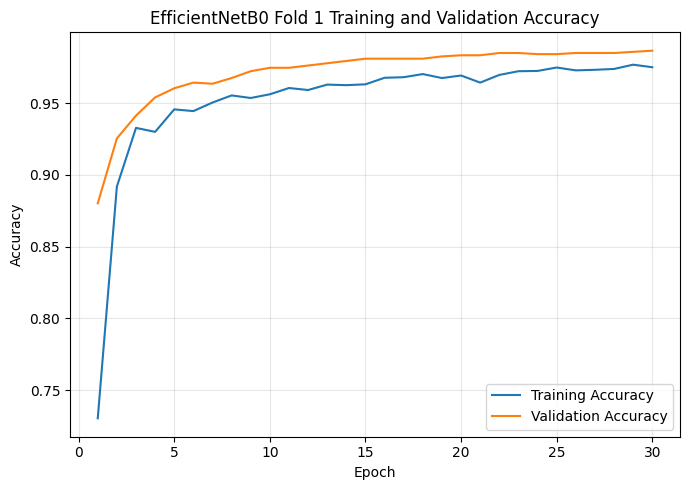

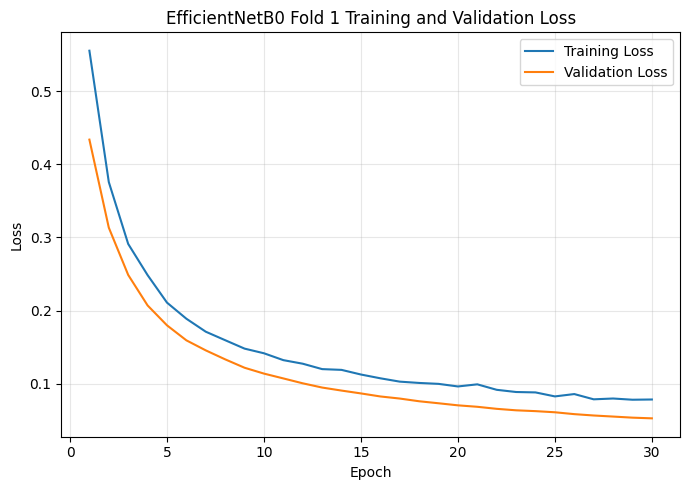

History CSV saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/training_history/EfficientNetB0_fold_1_history.csv
Accuracy graph saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_1_accuracy.png
Loss graph saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_1_loss.png
40/40 ━━━━━━━━━━━━━━━━━━━━ 18s 382ms/step

FOLD 1 VALIDATION RESULTS
Accuracy : 0.9865
Precision: 0.9932
Recall   : 0.9783
F1-Score : 0.9857
AUC      : 0.9996

Classification Report:

                      precision    recall  f1-score   support

encroachment_present     0.9806    0.9939    0.9872       661
     no_encroachment     0.9932    0.9783    0.9857       599

            accuracy                         0.9865      1260
           macro avg     0.9869    0.9861    0.9865      1260
        weighted avg     0.9866    0.9865    0.9865      1260

Validation predictions s

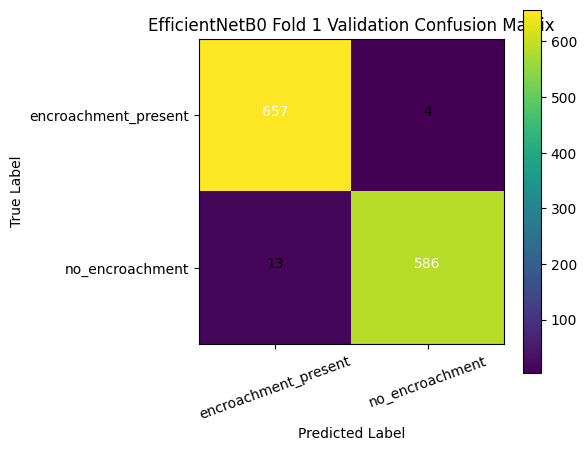

Confusion matrix saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_1_validation_confusion_matrix.png


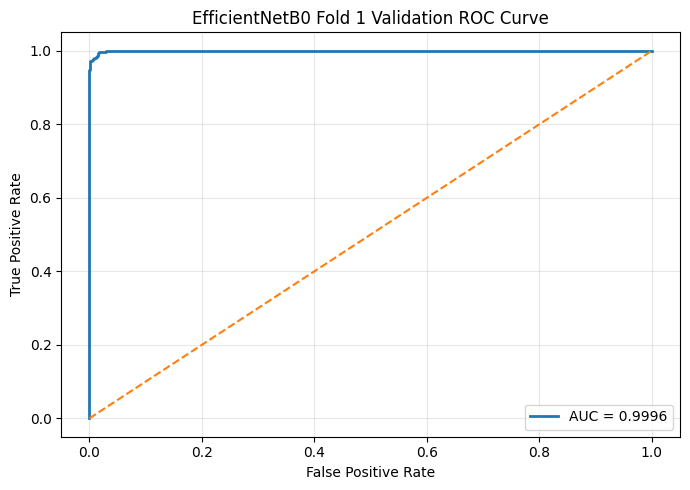

ROC curve saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_1_validation_roc_curve.png
Metrics JSON saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/metrics/EfficientNetB0_fold_1_validation_metrics.json
35/35 ━━━━━━━━━━━━━━━━━━━━ 218s 6s/step

FOLD 1 TEST RESULTS
Accuracy : 0.9802
Precision: 0.9941
Recall   : 0.9640
F1-Score : 0.9788
AUC      : 0.9994

Classification Report:

                      precision    recall  f1-score   support

encroachment_present     0.9683    0.9949    0.9814       584
     no_encroachment     0.9941    0.9640    0.9788       528

            accuracy                         0.9802      1112
           macro avg     0.9812    0.9794    0.9801      1112
        weighted avg     0.9806    0.9802    0.9802      1112

Test predictions saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/predictions/EfficientNetB0_fold_1_test_predictions.csv

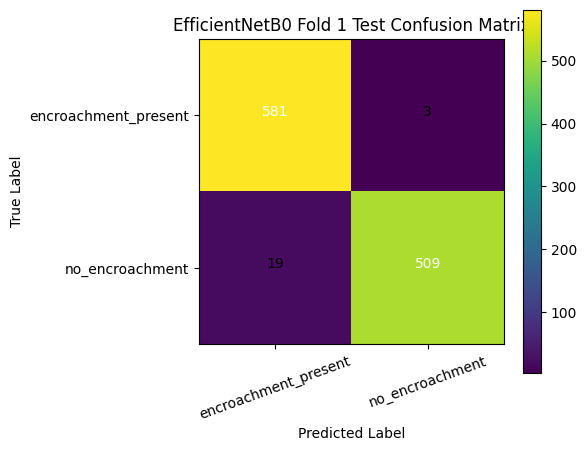

Confusion matrix saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_1_test_confusion_matrix.png


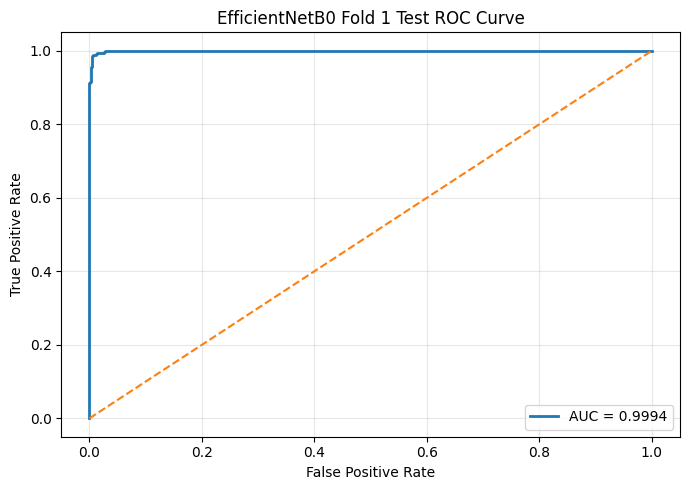

ROC curve saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_1_test_roc_curve.png
Metrics JSON saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/metrics/EfficientNetB0_fold_1_test_metrics.json

EfficientNetB0 FOLD 1 COMPLETED
Model saved at:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/saved_models/EfficientNetB0_fold_1.keras

Summary saved at:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/metrics/EfficientNetB0_fold_1_summary.csv

Validation metrics:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive
0,EfficientNetB0,1,validation,None,0.986508,0.99322,0.978297,0.985702,0.999576,657,4,13,586



Independent test metrics:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive
0,EfficientNetB0,1,test,None,0.980216,0.994141,0.964015,0.978846,0.999381,581,3,19,509


In [ ]:
# =====================================================
# STEP 7: TRAIN AND EVALUATE EfficientNetB0 FOLD 1
# =====================================================

FOLD_NUMBER = 1

print("=" * 75)
print(f"STARTING EfficientNetB0 FOLD {FOLD_NUMBER}")
print("=" * 75)


# -----------------------------------------------------
# 1. Prepare Fold 1 train and validation dataframes
# -----------------------------------------------------

fold_train_df = development_df[
    development_df["fold_id"] != FOLD_NUMBER
].reset_index(drop=True)

fold_val_df = development_df[
    development_df["fold_id"] == FOLD_NUMBER
].reset_index(drop=True)


print("Training images:", len(fold_train_df))
print("Validation images:", len(fold_val_df))
print("Independent test images:", len(test_df))


# -----------------------------------------------------
# 2. Create TensorFlow datasets
# -----------------------------------------------------

fold_train_dataset = create_tf_dataset(
    dataframe=fold_train_df,
    training=True
)

fold_val_dataset = create_tf_dataset(
    dataframe=fold_val_df,
    training=False
)


# -----------------------------------------------------
# 3. Clear old model and build a fresh model
# -----------------------------------------------------
# Every fold must start from the same ImageNet weights.
# Fold 1 must not continue from Step 4's temporary model.

tf.keras.backend.clear_session()

tf.random.set_seed(
    SEED + FOLD_NUMBER
)

np.random.seed(
    SEED + FOLD_NUMBER
)

random.seed(
    SEED + FOLD_NUMBER
)

fold_model, fold_backbone = (
    build_efficientnetb0_model()
)


print("\nFresh model created for Fold 1.")
print("Backbone trainable:", fold_backbone.trainable)


# -----------------------------------------------------
# 4. Train for the full 30 epochs
# -----------------------------------------------------
# No EarlyStopping
# No learning-rate scheduler
# No ModelCheckpoint
# Same as the previous experimental setup

history_fold_1 = fold_model.fit(
    fold_train_dataset,

    validation_data=fold_val_dataset,

    epochs=EPOCHS,

    verbose=1
)


# -----------------------------------------------------
# 5. Save final Fold 1 model
# -----------------------------------------------------

fold_1_model_path = save_fold_model(
    model=fold_model,
    fold_number=FOLD_NUMBER
)


# -----------------------------------------------------
# 6. Save and show training history
# -----------------------------------------------------

history_fold_1_df = plot_and_save_history(
    history=history_fold_1,
    fold_number=FOLD_NUMBER
)


# -----------------------------------------------------
# 7. Evaluate validation set
# -----------------------------------------------------

fold_1_validation_results = (
    evaluate_and_save_fold(
        model=fold_model,
        dataframe=fold_val_df,
        dataset=fold_val_dataset,
        fold_number=FOLD_NUMBER,
        dataset_name="validation"
    )
)


# -----------------------------------------------------
# 8. Evaluate independent test set
# -----------------------------------------------------

fold_1_test_results = (
    evaluate_and_save_fold(
        model=fold_model,
        dataframe=test_df,
        dataset=test_tf_dataset,
        fold_number=FOLD_NUMBER,
        dataset_name="test"
    )
)


# -----------------------------------------------------
# 9. Save combined Fold 1 metric summary
# -----------------------------------------------------

fold_1_summary_df = pd.DataFrame([
    fold_1_validation_results["metrics"],
    fold_1_test_results["metrics"]
])

fold_1_summary_path = (
    EFFICIENTNET_METRIC_DIR /
    "EfficientNetB0_fold_1_summary.csv"
)

fold_1_summary_df.to_csv(
    fold_1_summary_path,
    index=False
)


print("\n" + "=" * 75)
print("EfficientNetB0 FOLD 1 COMPLETED")
print("=" * 75)

print("Model saved at:")
print(fold_1_model_path)

print("\nSummary saved at:")
print(fold_1_summary_path)

print("\nValidation metrics:")
display(
    pd.DataFrame([
        fold_1_validation_results["metrics"]
    ])
)

print("\nIndependent test metrics:")
display(
    pd.DataFrame([
        fold_1_test_results["metrics"]
    ])
)

STARTING EfficientNetB0 FOLD 2
Training images: 5039
Validation images: 1260
Independent test images: 1112

Fresh model created for Fold 2.
Backbone trainable: False
Epoch 1/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 77s 417ms/step - accuracy: 0.6726 - auc: 0.7429 - loss: 0.6063 - precision: 0.6637 - recall: 0.6293 - val_accuracy: 0.8357 - val_auc: 0.9466 - val_loss: 0.4892 - val_precision: 0.9537 - val_recall: 0.6878
Epoch 2/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 78s 492ms/step - accuracy: 0.8750 - auc: 0.9493 - loss: 0.4135 - precision: 0.9001 - recall: 0.8287 - val_accuracy: 0.8984 - val_auc: 0.9854 - val_loss: 0.3506 - val_precision: 0.9758 - val_recall: 0.8063
Epoch 3/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 68s 402ms/step - accuracy: 0.9190 - auc: 0.9766 - loss: 0.3128 - precision: 0.9295 - recall: 0.8976 - val_accuracy: 0.9357 - val_auc: 0.9921 - val_loss: 0.2718 - val_precision: 0.9796 - val_recall: 0.8831
Epoch 4/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 89s 450ms/step - accuracy: 0.9290 - auc: 0.9829 - loss: 0.2

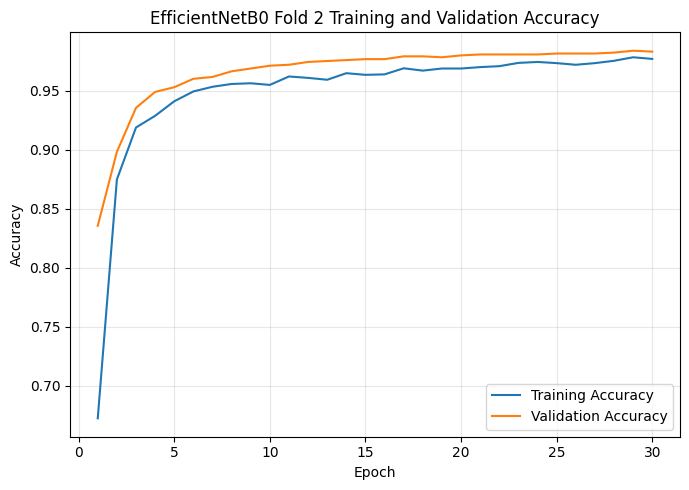

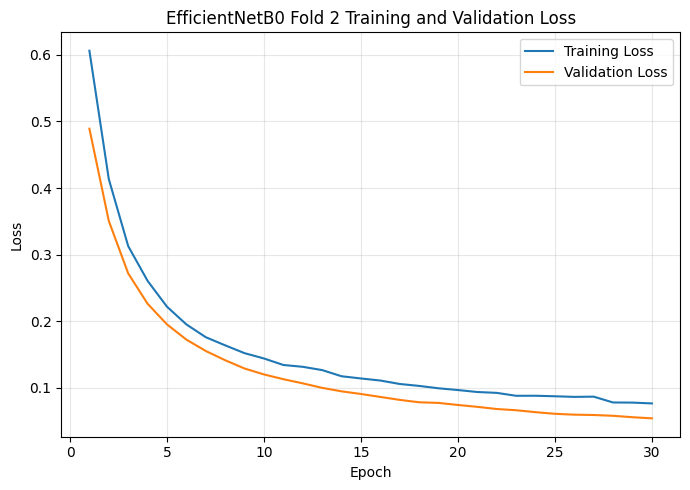

History CSV saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/training_history/EfficientNetB0_fold_2_history.csv
Accuracy graph saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_2_accuracy.png
Loss graph saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_2_loss.png
40/40 ━━━━━━━━━━━━━━━━━━━━ 17s 362ms/step

FOLD 2 VALIDATION RESULTS
Accuracy : 0.9833
Precision: 0.9882
Recall   : 0.9766
F1-Score : 0.9824
AUC      : 0.9994

Classification Report:

                      precision    recall  f1-score   support

encroachment_present     0.9790    0.9894    0.9842       661
     no_encroachment     0.9882    0.9766    0.9824       599

            accuracy                         0.9833      1260
           macro avg     0.9836    0.9830    0.9833      1260
        weighted avg     0.9834    0.9833    0.9833      1260

Validation predictions s

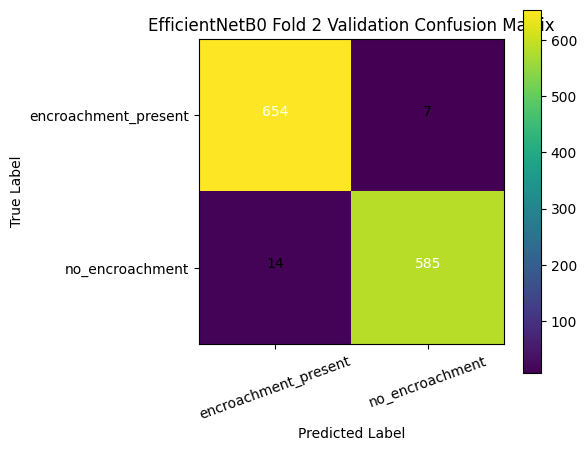

Confusion matrix saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_2_validation_confusion_matrix.png


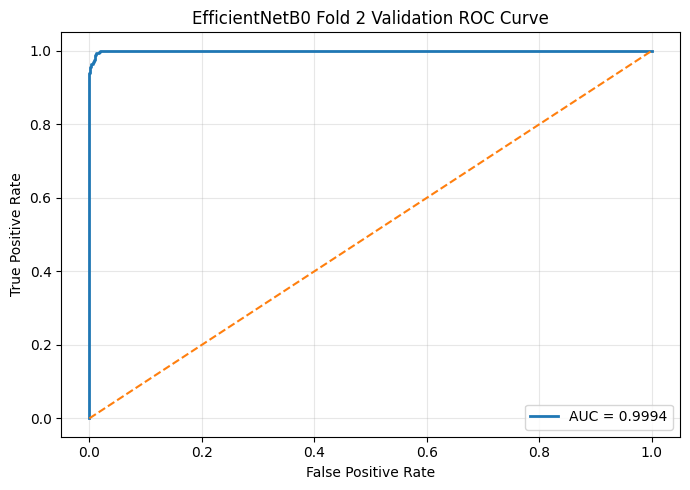

ROC curve saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_2_validation_roc_curve.png
Metrics JSON saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/metrics/EfficientNetB0_fold_2_validation_metrics.json
35/35 ━━━━━━━━━━━━━━━━━━━━ 12s 340ms/step

FOLD 2 TEST RESULTS
Accuracy : 0.9820
Precision: 0.9942
Recall   : 0.9678
F1-Score : 0.9808
AUC      : 0.9994

Classification Report:

                      precision    recall  f1-score   support

encroachment_present     0.9716    0.9949    0.9831       584
     no_encroachment     0.9942    0.9678    0.9808       528

            accuracy                         0.9820      1112
           macro avg     0.9829    0.9813    0.9819      1112
        weighted avg     0.9823    0.9820    0.9820      1112

Test predictions saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/predictions/EfficientNetB0_fold_2_test_predictions.c

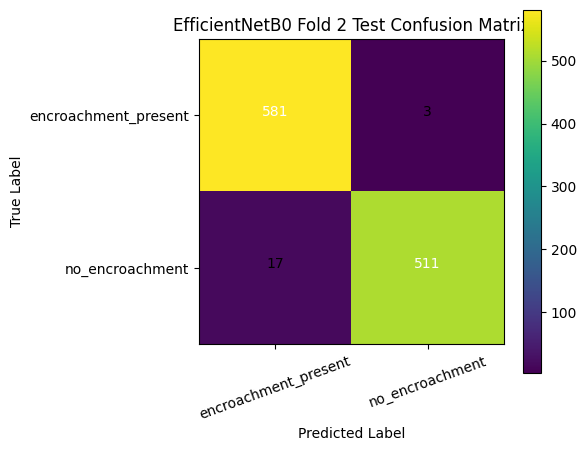

Confusion matrix saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_2_test_confusion_matrix.png


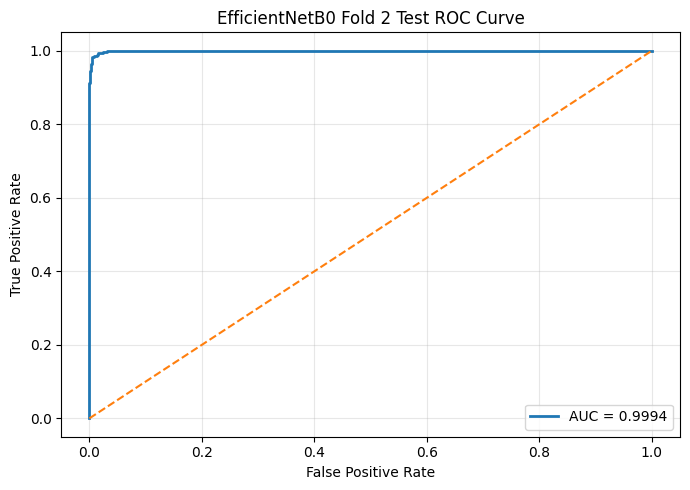

ROC curve saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_2_test_roc_curve.png
Metrics JSON saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/metrics/EfficientNetB0_fold_2_test_metrics.json

EfficientNetB0 FOLD 2 COMPLETED
Model saved at:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/saved_models/EfficientNetB0_fold_2.keras

Summary saved at:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/metrics/EfficientNetB0_fold_2_summary.csv

Validation metrics:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive
0,EfficientNetB0,2,validation,None,0.983333,0.988176,0.976628,0.982368,0.999434,654,7,14,585



Independent test metrics:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive
0,EfficientNetB0,2,test,None,0.982014,0.994163,0.967803,0.980806,0.999403,581,3,17,511


In [ ]:
# =====================================================
# STEP 8: TRAIN AND EVALUATE EfficientNetB0 FOLD 2
# =====================================================

FOLD_NUMBER = 2

print("=" * 75)
print(f"STARTING EfficientNetB0 FOLD {FOLD_NUMBER}")
print("=" * 75)


# -----------------------------------------------------
# 1. Prepare Fold 2 train and validation dataframes
# -----------------------------------------------------

fold_train_df = development_df[
    development_df["fold_id"] != FOLD_NUMBER
].reset_index(drop=True)

fold_val_df = development_df[
    development_df["fold_id"] == FOLD_NUMBER
].reset_index(drop=True)


print("Training images:", len(fold_train_df))
print("Validation images:", len(fold_val_df))
print("Independent test images:", len(test_df))


# -----------------------------------------------------
# 2. Create TensorFlow datasets
# -----------------------------------------------------

fold_train_dataset = create_tf_dataset(
    dataframe=fold_train_df,
    training=True
)

fold_val_dataset = create_tf_dataset(
    dataframe=fold_val_df,
    training=False
)


# -----------------------------------------------------
# 3. Clear previous model and build a fresh model
# -----------------------------------------------------

tf.keras.backend.clear_session()

tf.random.set_seed(SEED + FOLD_NUMBER)
np.random.seed(SEED + FOLD_NUMBER)
random.seed(SEED + FOLD_NUMBER)

fold_model, fold_backbone = build_efficientnetb0_model()

print("\nFresh model created for Fold 2.")
print("Backbone trainable:", fold_backbone.trainable)


# -----------------------------------------------------
# 4. Train Fold 2
# -----------------------------------------------------

history_fold_2 = fold_model.fit(
    fold_train_dataset,
    validation_data=fold_val_dataset,
    epochs=EPOCHS,
    verbose=1
)


# -----------------------------------------------------
# 5. Save final Fold 2 model
# -----------------------------------------------------

fold_2_model_path = save_fold_model(
    model=fold_model,
    fold_number=FOLD_NUMBER
)


# -----------------------------------------------------
# 6. Save and show training history
# -----------------------------------------------------

history_fold_2_df = plot_and_save_history(
    history=history_fold_2,
    fold_number=FOLD_NUMBER
)


# -----------------------------------------------------
# 7. Evaluate validation set
# -----------------------------------------------------

fold_2_validation_results = evaluate_and_save_fold(
    model=fold_model,
    dataframe=fold_val_df,
    dataset=fold_val_dataset,
    fold_number=FOLD_NUMBER,
    dataset_name="validation"
)


# -----------------------------------------------------
# 8. Evaluate independent test set
# -----------------------------------------------------

fold_2_test_results = evaluate_and_save_fold(
    model=fold_model,
    dataframe=test_df,
    dataset=test_tf_dataset,
    fold_number=FOLD_NUMBER,
    dataset_name="test"
)


# -----------------------------------------------------
# 9. Save combined Fold 2 metric summary
# -----------------------------------------------------

fold_2_summary_df = pd.DataFrame([
    fold_2_validation_results["metrics"],
    fold_2_test_results["metrics"]
])

fold_2_summary_path = (
    EFFICIENTNET_METRIC_DIR /
    "EfficientNetB0_fold_2_summary.csv"
)

fold_2_summary_df.to_csv(
    fold_2_summary_path,
    index=False
)


print("\n" + "=" * 75)
print("EfficientNetB0 FOLD 2 COMPLETED")
print("=" * 75)

print("Model saved at:")
print(fold_2_model_path)

print("\nSummary saved at:")
print(fold_2_summary_path)

print("\nValidation metrics:")
display(
    pd.DataFrame([
        fold_2_validation_results["metrics"]
    ])
)

print("\nIndependent test metrics:")
display(
    pd.DataFrame([
        fold_2_test_results["metrics"]
    ])
)


STARTING EfficientNetB0 FOLD 3
Training images: 5039
Validation images: 1260
Independent test images: 1112

Fresh model created for Fold 3.
Backbone trainable: False
Epoch 1/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 84s 446ms/step - accuracy: 0.6063 - auc: 0.6417 - loss: 0.6689 - precision: 0.5694 - recall: 0.7026 - val_accuracy: 0.8698 - val_auc: 0.9415 - val_loss: 0.4897 - val_precision: 0.9222 - val_recall: 0.7926
Epoch 2/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 87s 477ms/step - accuracy: 0.8486 - auc: 0.9285 - loss: 0.4453 - precision: 0.8655 - recall: 0.8066 - val_accuracy: 0.9317 - val_auc: 0.9855 - val_loss: 0.3458 - val_precision: 0.9758 - val_recall: 0.8779
Epoch 3/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 78s 449ms/step - accuracy: 0.9139 - auc: 0.9713 - loss: 0.3350 - precision: 0.9231 - recall: 0.8931 - val_accuracy: 0.9429 - val_auc: 0.9916 - val_loss: 0.2699 - val_precision: 0.9817 - val_recall: 0.8963
Epoch 4/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 74s 395ms/step - accuracy: 0.9345 - auc: 0.9830 - loss: 0.

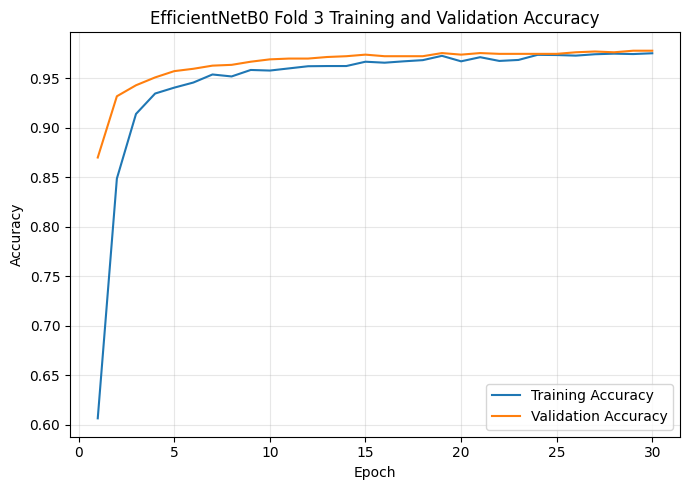

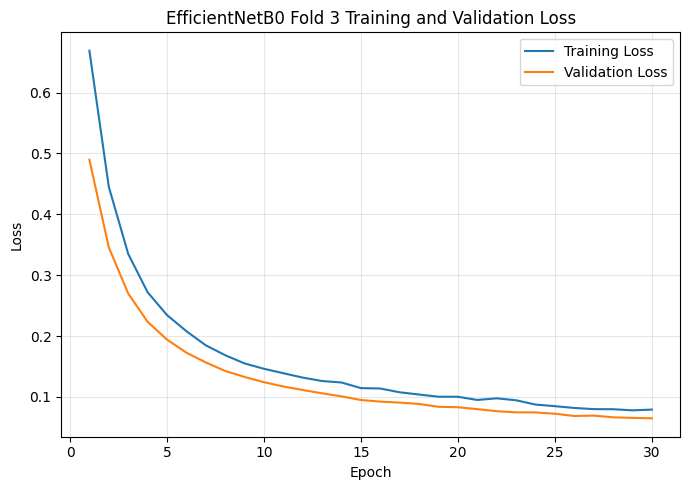

History CSV saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/training_history/EfficientNetB0_fold_3_history.csv
Accuracy graph saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_3_accuracy.png
Loss graph saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_3_loss.png
40/40 ━━━━━━━━━━━━━━━━━━━━ 17s 367ms/step

FOLD 3 VALIDATION RESULTS
Accuracy : 0.9778
Precision: 0.9880
Recall   : 0.9649
F1-Score : 0.9763
AUC      : 0.9986

Classification Report:

                      precision    recall  f1-score   support

encroachment_present     0.9689    0.9894    0.9791       662
     no_encroachment     0.9880    0.9649    0.9763       598

            accuracy                         0.9778      1260
           macro avg     0.9785    0.9772    0.9777      1260
        weighted avg     0.9780    0.9778    0.9778      1260

Validation predictions s

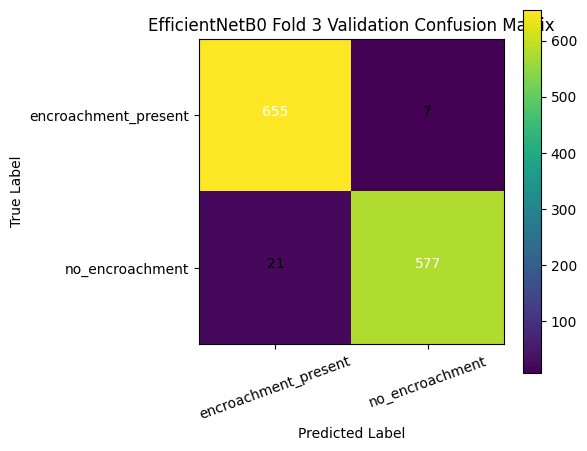

Confusion matrix saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_3_validation_confusion_matrix.png


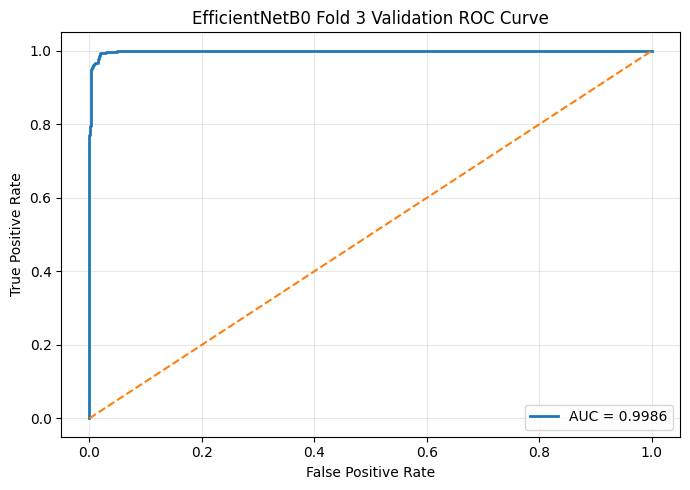

ROC curve saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_3_validation_roc_curve.png
Metrics JSON saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/metrics/EfficientNetB0_fold_3_validation_metrics.json
35/35 ━━━━━━━━━━━━━━━━━━━━ 12s 339ms/step

FOLD 3 TEST RESULTS
Accuracy : 0.9820
Precision: 0.9942
Recall   : 0.9678
F1-Score : 0.9808
AUC      : 0.9994

Classification Report:

                      precision    recall  f1-score   support

encroachment_present     0.9716    0.9949    0.9831       584
     no_encroachment     0.9942    0.9678    0.9808       528

            accuracy                         0.9820      1112
           macro avg     0.9829    0.9813    0.9819      1112
        weighted avg     0.9823    0.9820    0.9820      1112

Test predictions saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/predictions/EfficientNetB0_fold_3_test_predictions.c

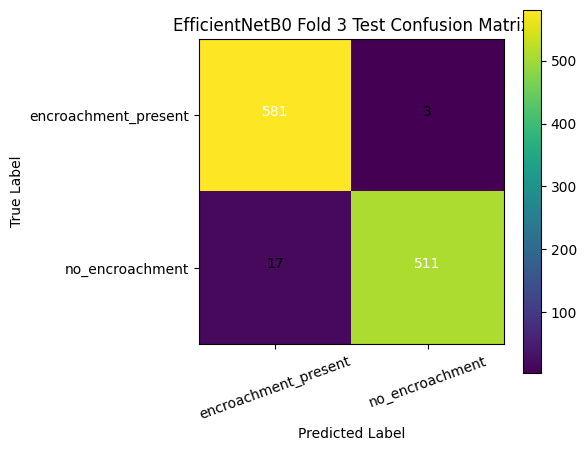

Confusion matrix saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_3_test_confusion_matrix.png


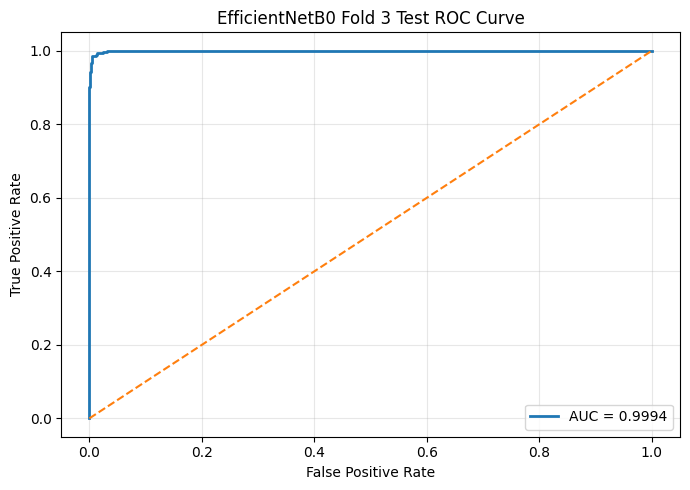

ROC curve saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_3_test_roc_curve.png
Metrics JSON saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/metrics/EfficientNetB0_fold_3_test_metrics.json

EfficientNetB0 FOLD 3 COMPLETED
Model saved at:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/saved_models/EfficientNetB0_fold_3.keras

Summary saved at:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/metrics/EfficientNetB0_fold_3_summary.csv

Validation metrics:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive
0,EfficientNetB0,3,validation,None,0.977778,0.988014,0.964883,0.976311,0.998644,655,7,21,577



Independent test metrics:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive
0,EfficientNetB0,3,test,None,0.982014,0.994163,0.967803,0.980806,0.9994,581,3,17,511



STARTING EfficientNetB0 FOLD 4
Training images: 5039
Validation images: 1260
Independent test images: 1112

Fresh model created for Fold 4.
Backbone trainable: False
Epoch 1/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 77s 421ms/step - accuracy: 0.6775 - auc: 0.7398 - loss: 0.6046 - precision: 0.6654 - recall: 0.6462 - val_accuracy: 0.8556 - val_auc: 0.9471 - val_loss: 0.4558 - val_precision: 0.9111 - val_recall: 0.7709
Epoch 2/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 70s 446ms/step - accuracy: 0.8607 - auc: 0.9424 - loss: 0.4123 - precision: 0.8790 - recall: 0.8195 - val_accuracy: 0.9190 - val_auc: 0.9799 - val_loss: 0.3289 - val_precision: 0.9444 - val_recall: 0.8813
Epoch 3/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 62s 394ms/step - accuracy: 0.9111 - auc: 0.9725 - loss: 0.3162 - precision: 0.9201 - recall: 0.8901 - val_accuracy: 0.9373 - val_auc: 0.9875 - val_loss: 0.2602 - val_precision: 0.9529 - val_recall: 0.9130
Epoch 4/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 62s 394ms/step - accuracy: 0.9286 - auc: 0.9816 - loss: 0.

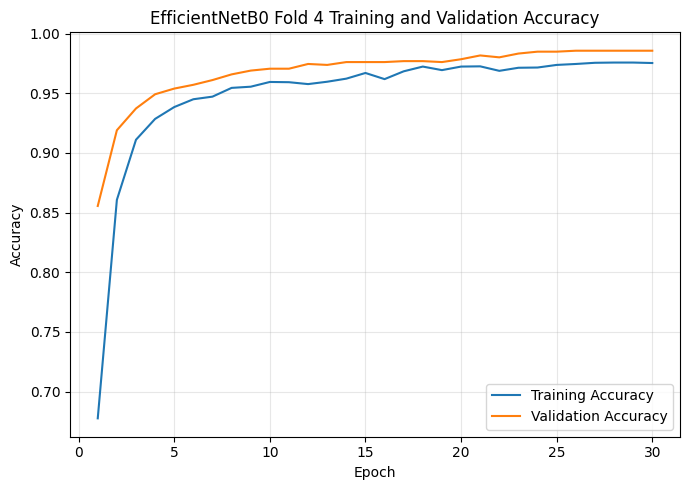

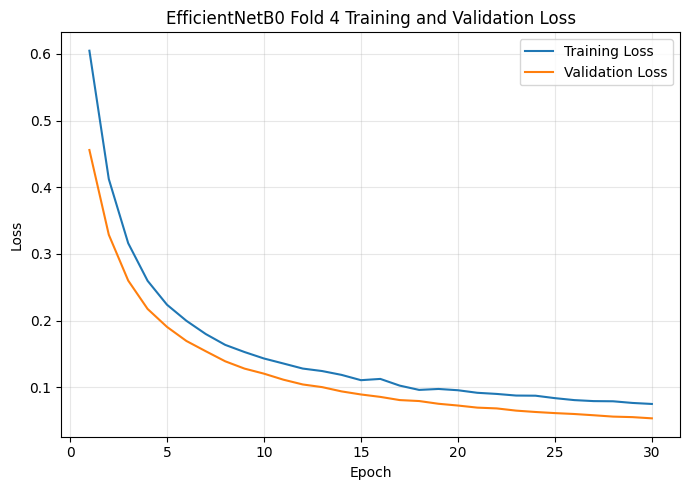

History CSV saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/training_history/EfficientNetB0_fold_4_history.csv
Accuracy graph saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_4_accuracy.png
Loss graph saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_4_loss.png
40/40 ━━━━━━━━━━━━━━━━━━━━ 17s 366ms/step

FOLD 4 VALIDATION RESULTS
Accuracy : 0.9857
Precision: 0.9866
Recall   : 0.9833
F1-Score : 0.9849
AUC      : 0.9993

Classification Report:

                      precision    recall  f1-score   support

encroachment_present     0.9849    0.9879    0.9864       662
     no_encroachment     0.9866    0.9833    0.9849       598

            accuracy                         0.9857      1260
           macro avg     0.9858    0.9856    0.9857      1260
        weighted avg     0.9857    0.9857    0.9857      1260

Validation predictions s

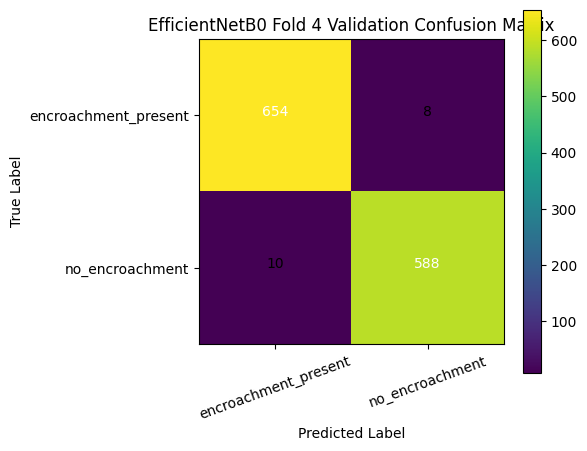

Confusion matrix saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_4_validation_confusion_matrix.png


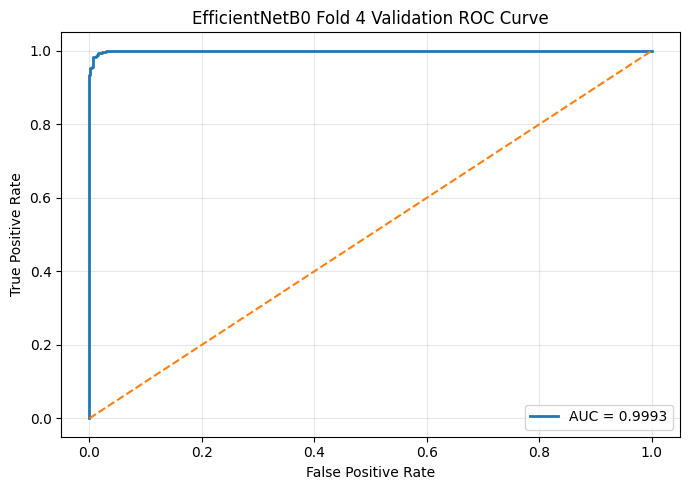

ROC curve saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_4_validation_roc_curve.png
Metrics JSON saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/metrics/EfficientNetB0_fold_4_validation_metrics.json
35/35 ━━━━━━━━━━━━━━━━━━━━ 12s 339ms/step

FOLD 4 TEST RESULTS
Accuracy : 0.9820
Precision: 0.9942
Recall   : 0.9678
F1-Score : 0.9808
AUC      : 0.9992

Classification Report:

                      precision    recall  f1-score   support

encroachment_present     0.9716    0.9949    0.9831       584
     no_encroachment     0.9942    0.9678    0.9808       528

            accuracy                         0.9820      1112
           macro avg     0.9829    0.9813    0.9819      1112
        weighted avg     0.9823    0.9820    0.9820      1112

Test predictions saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/predictions/EfficientNetB0_fold_4_test_predictions.c

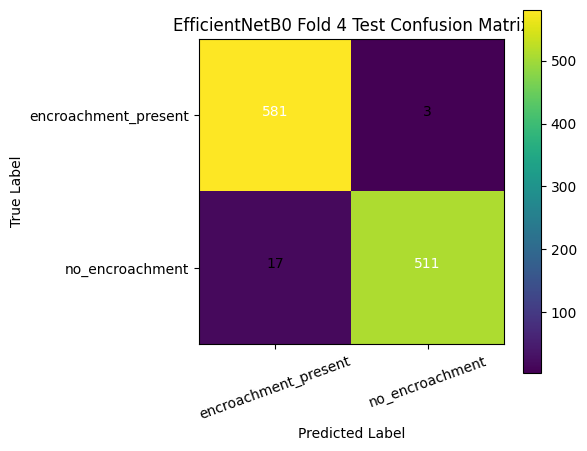

Confusion matrix saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_4_test_confusion_matrix.png


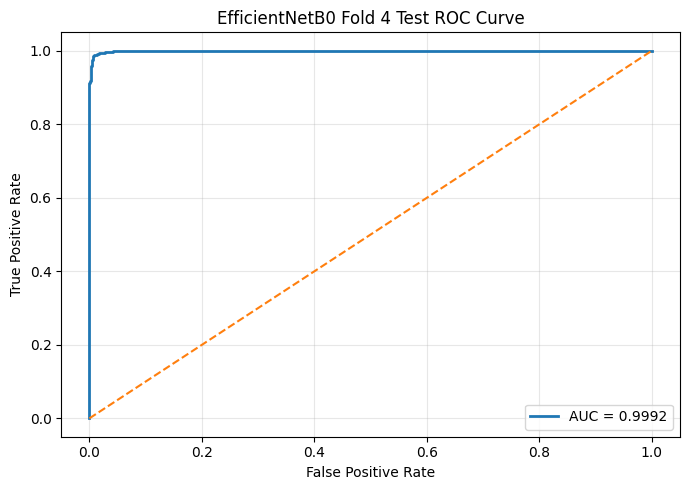

ROC curve saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_4_test_roc_curve.png
Metrics JSON saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/metrics/EfficientNetB0_fold_4_test_metrics.json

EfficientNetB0 FOLD 4 COMPLETED
Model saved at:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/saved_models/EfficientNetB0_fold_4.keras

Summary saved at:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/metrics/EfficientNetB0_fold_4_summary.csv

Validation metrics:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive
0,EfficientNetB0,4,validation,None,0.985714,0.986577,0.983278,0.984925,0.999348,654,8,10,588



Independent test metrics:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive
0,EfficientNetB0,4,test,None,0.982014,0.994163,0.967803,0.980806,0.999167,581,3,17,511



STARTING EfficientNetB0 FOLD 5
Training images: 5040
Validation images: 1259
Independent test images: 1112

Fresh model created for Fold 5.
Backbone trainable: False
Epoch 1/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 76s 412ms/step - accuracy: 0.7605 - auc: 0.8399 - loss: 0.5318 - precision: 0.7518 - recall: 0.7402 - val_accuracy: 0.8936 - val_auc: 0.9667 - val_loss: 0.4189 - val_precision: 0.8602 - val_recall: 0.9264
Epoch 2/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 87s 446ms/step - accuracy: 0.8897 - auc: 0.9605 - loss: 0.3692 - precision: 0.9010 - recall: 0.8626 - val_accuracy: 0.9349 - val_auc: 0.9853 - val_loss: 0.3044 - val_precision: 0.9358 - val_recall: 0.9264
Epoch 3/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 61s 388ms/step - accuracy: 0.9218 - auc: 0.9772 - loss: 0.2899 - precision: 0.9274 - recall: 0.9064 - val_accuracy: 0.9436 - val_auc: 0.9897 - val_loss: 0.2454 - val_precision: 0.9551 - val_recall: 0.9247
Epoch 4/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 71s 453ms/step - accuracy: 0.9357 - auc: 0.9846 - loss: 0.

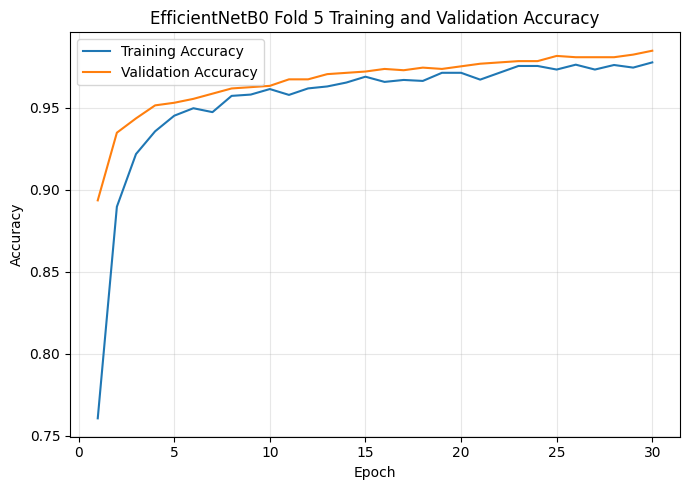

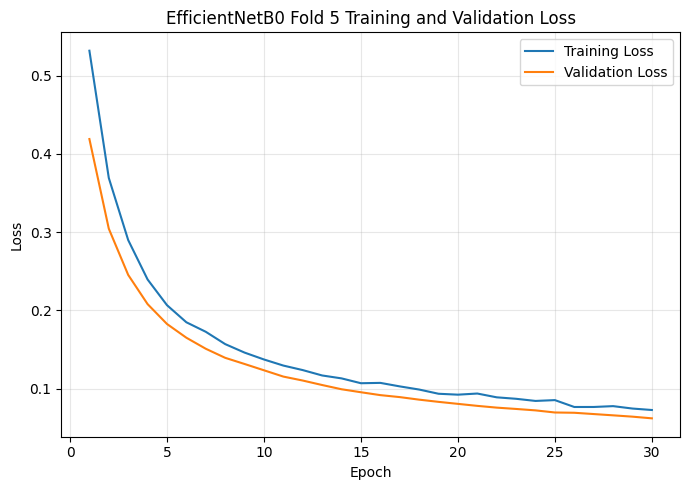

History CSV saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/training_history/EfficientNetB0_fold_5_history.csv
Accuracy graph saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_5_accuracy.png
Loss graph saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_5_loss.png
40/40 ━━━━━━━━━━━━━━━━━━━━ 18s 351ms/step

FOLD 5 VALIDATION RESULTS
Accuracy : 0.9849
Precision: 0.9898
Recall   : 0.9783
F1-Score : 0.9840
AUC      : 0.9990

Classification Report:

                      precision    recall  f1-score   support

encroachment_present     0.9805    0.9909    0.9857       661
     no_encroachment     0.9898    0.9783    0.9840       598

            accuracy                         0.9849      1259
           macro avg     0.9852    0.9846    0.9849      1259
        weighted avg     0.9850    0.9849    0.9849      1259

Validation predictions s

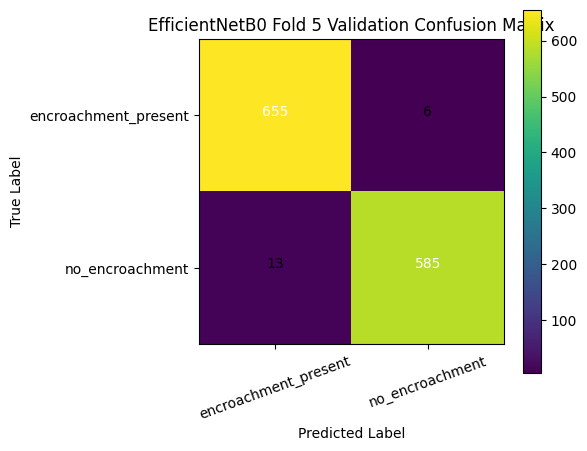

Confusion matrix saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_5_validation_confusion_matrix.png


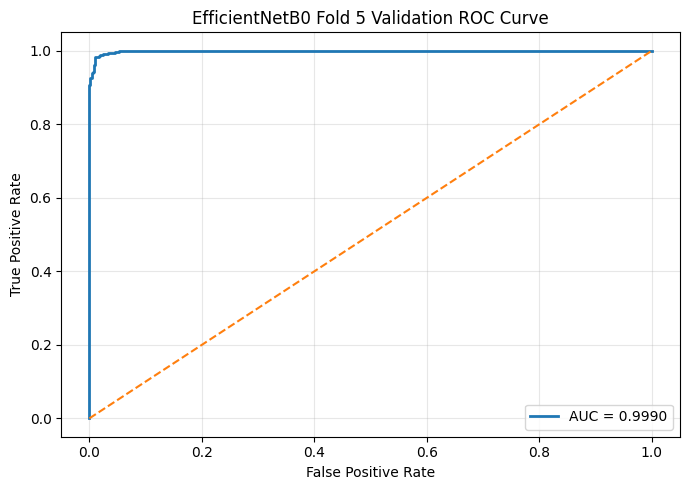

ROC curve saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_5_validation_roc_curve.png
Metrics JSON saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/metrics/EfficientNetB0_fold_5_validation_metrics.json
35/35 ━━━━━━━━━━━━━━━━━━━━ 10s 298ms/step

FOLD 5 TEST RESULTS
Accuracy : 0.9829
Precision: 0.9942
Recall   : 0.9697
F1-Score : 0.9818
AUC      : 0.9993

Classification Report:

                      precision    recall  f1-score   support

encroachment_present     0.9732    0.9949    0.9839       584
     no_encroachment     0.9942    0.9697    0.9818       528

            accuracy                         0.9829      1112
           macro avg     0.9837    0.9823    0.9828      1112
        weighted avg     0.9832    0.9829    0.9829      1112

Test predictions saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/predictions/EfficientNetB0_fold_5_test_predictions.c

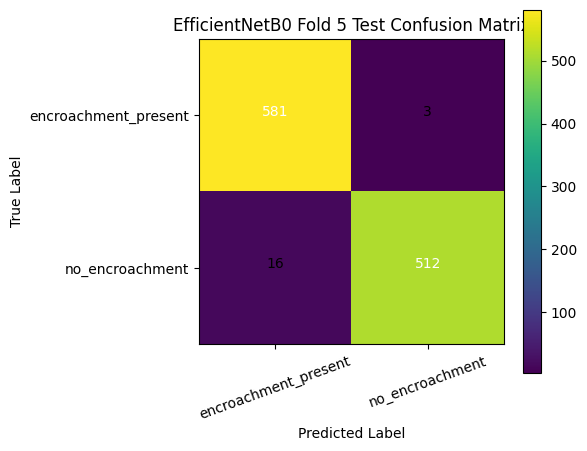

Confusion matrix saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_5_test_confusion_matrix.png


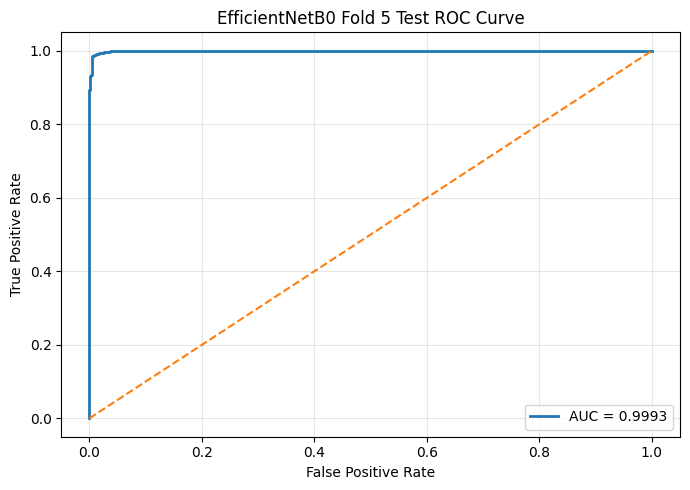

ROC curve saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/figures/EfficientNetB0_fold_5_test_roc_curve.png
Metrics JSON saved: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/metrics/EfficientNetB0_fold_5_test_metrics.json

EfficientNetB0 FOLD 5 COMPLETED
Model saved at:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/saved_models/EfficientNetB0_fold_5.keras

Summary saved at:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/metrics/EfficientNetB0_fold_5_summary.csv

Validation metrics:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive
0,EfficientNetB0,5,validation,None,0.984909,0.989848,0.978261,0.98402,0.998968,655,6,13,585



Independent test metrics:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive
0,EfficientNetB0,5,test,None,0.982914,0.994175,0.969697,0.981783,0.999293,581,3,16,512



EfficientNetB0 FOLDS 3, 4, AND 5 COMPLETED


In [ ]:
# =====================================================
# STEP 9–11: TRAIN AND EVALUATE FOLDS 3, 4, AND 5
# =====================================================

# Fold-wise outputs temporarily store করার জন্য
fold_validation_results_all = {}
fold_test_results_all = {}
fold_histories_all = {}
fold_summary_paths_all = {}


def run_efficientnet_fold(fold_number):
    """
    Train, evaluate, and save one EfficientNetB0 fold
    using the same pipeline and experimental settings.
    """

    print("\n" + "=" * 75)
    print(f"STARTING EfficientNetB0 FOLD {fold_number}")
    print("=" * 75)

    # -------------------------------------------------
    # 1. Prepare training and validation dataframes
    # -------------------------------------------------

    current_train_df = development_df[
        development_df["fold_id"] != fold_number
    ].reset_index(drop=True)

    current_val_df = development_df[
        development_df["fold_id"] == fold_number
    ].reset_index(drop=True)

    print("Training images:", len(current_train_df))
    print("Validation images:", len(current_val_df))
    print("Independent test images:", len(test_df))

    # -------------------------------------------------
    # 2. Create TensorFlow datasets
    # -------------------------------------------------

    current_train_dataset = create_tf_dataset(
        dataframe=current_train_df,
        training=True
    )

    current_val_dataset = create_tf_dataset(
        dataframe=current_val_df,
        training=False
    )

    # -------------------------------------------------
    # 3. Clear previous model and create fresh model
    # -------------------------------------------------

    tf.keras.backend.clear_session()

    tf.random.set_seed(SEED + fold_number)
    np.random.seed(SEED + fold_number)
    random.seed(SEED + fold_number)

    current_model, current_backbone = (
        build_efficientnetb0_model()
    )

    print(f"\nFresh model created for Fold {fold_number}.")
    print("Backbone trainable:", current_backbone.trainable)

    # -------------------------------------------------
    # 4. Train current fold
    # -------------------------------------------------
    # Same setup:
    # No EarlyStopping
    # No scheduler
    # No checkpoint
    # Full EPOCHS

    current_history = current_model.fit(
        current_train_dataset,
        validation_data=current_val_dataset,
        epochs=EPOCHS,
        verbose=1
    )

    # -------------------------------------------------
    # 5. Save final fold model
    # -------------------------------------------------

    current_model_path = save_fold_model(
        model=current_model,
        fold_number=fold_number
    )

    # -------------------------------------------------
    # 6. Save and display training history
    # -------------------------------------------------

    current_history_df = plot_and_save_history(
        history=current_history,
        fold_number=fold_number
    )

    # -------------------------------------------------
    # 7. Evaluate fold validation set
    # -------------------------------------------------

    current_validation_results = evaluate_and_save_fold(
        model=current_model,
        dataframe=current_val_df,
        dataset=current_val_dataset,
        fold_number=fold_number,
        dataset_name="validation"
    )

    # -------------------------------------------------
    # 8. Evaluate independent test set
    # -------------------------------------------------

    current_test_results = evaluate_and_save_fold(
        model=current_model,
        dataframe=test_df,
        dataset=test_tf_dataset,
        fold_number=fold_number,
        dataset_name="test"
    )

    # -------------------------------------------------
    # 9. Save combined fold metric summary
    # -------------------------------------------------

    current_summary_df = pd.DataFrame([
        current_validation_results["metrics"],
        current_test_results["metrics"]
    ])

    current_summary_path = (
        EFFICIENTNET_METRIC_DIR /
        f"EfficientNetB0_fold_{fold_number}_summary.csv"
    )

    current_summary_df.to_csv(
        current_summary_path,
        index=False
    )

    # -------------------------------------------------
    # 10. Store outputs
    # -------------------------------------------------

    fold_validation_results_all[fold_number] = (
        current_validation_results
    )

    fold_test_results_all[fold_number] = (
        current_test_results
    )

    fold_histories_all[fold_number] = (
        current_history_df
    )

    fold_summary_paths_all[fold_number] = (
        current_summary_path
    )

    # -------------------------------------------------
    # 11. Display current fold results
    # -------------------------------------------------

    print("\n" + "=" * 75)
    print(f"EfficientNetB0 FOLD {fold_number} COMPLETED")
    print("=" * 75)

    print("Model saved at:")
    print(current_model_path)

    print("\nSummary saved at:")
    print(current_summary_path)

    print("\nValidation metrics:")
    display(
        pd.DataFrame([
            current_validation_results["metrics"]
        ])
    )

    print("\nIndependent test metrics:")
    display(
        pd.DataFrame([
            current_test_results["metrics"]
        ])
    )

    # Memory cleanup before next fold
    del current_model
    del current_backbone
    del current_train_dataset
    del current_val_dataset

    tf.keras.backend.clear_session()
    gc.collect()

    return current_summary_path


# =====================================================
# RUN FOLDS 3, 4, AND 5 SEQUENTIALLY
# =====================================================

import gc

for current_fold_number in [3, 4, 5]:
    run_efficientnet_fold(
        fold_number=current_fold_number
    )


print("\n" + "=" * 75)
print("EfficientNetB0 FOLDS 3, 4, AND 5 COMPLETED")
print("=" * 75)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
EfficientNetB0 FINAL POST-TRAINING ANALYSIS
All required EfficientNetB0 files were found.

Performance Table (Mean ± SD):


,Model,CV Loss,CV Accuracy (%),Precision (%),Recall (%),F1-Score (%),AUC
0,EfficientNetB0,nan ± nan,98.36 ± 0.35,98.92 ± 0.25,97.63 ± 0.68,98.27 ± 0.38,1.00 ± 0.00



Accuracy 95% Confidence Interval:


,Model,Mean Accuracy (%),Standard Deviation (%),95% CI Lower (%),95% CI Upper (%),Paper Format
0,EfficientNetB0,98.36484,0.348556,97.93205,98.797629,98.36% (97.93%–98.80%)


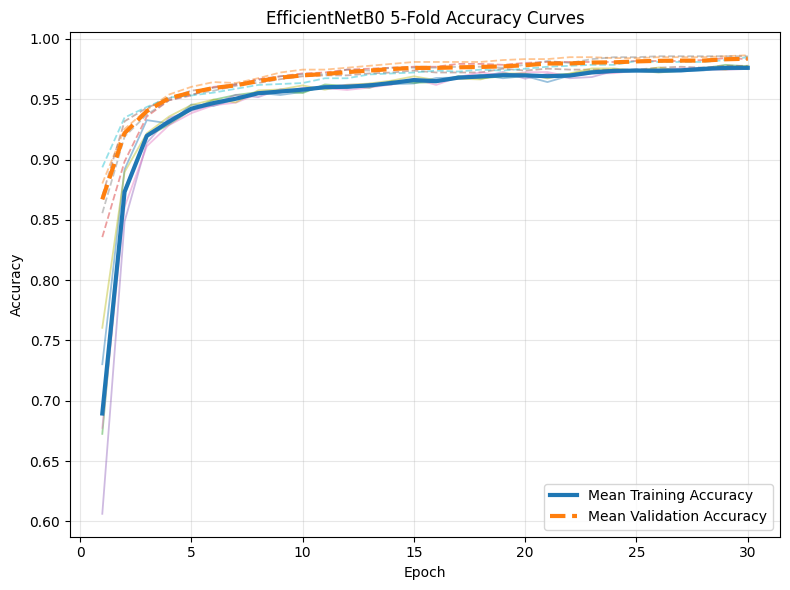

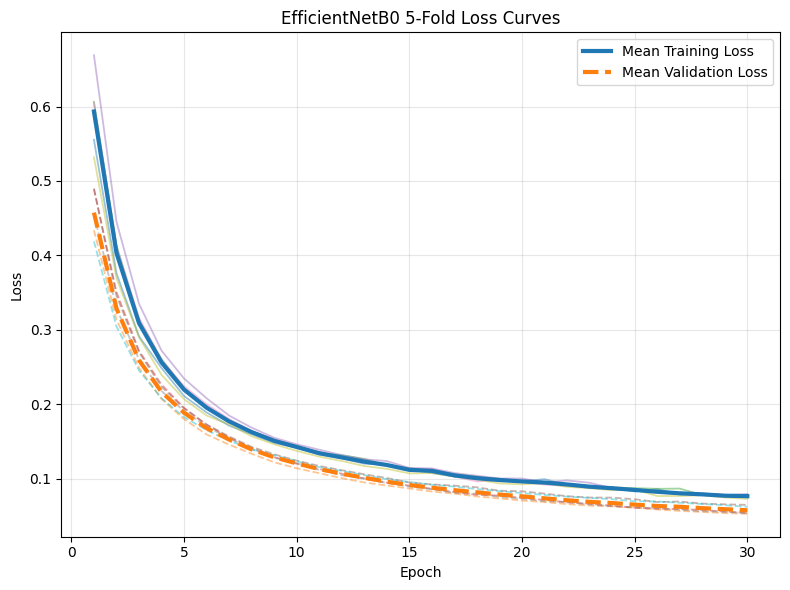

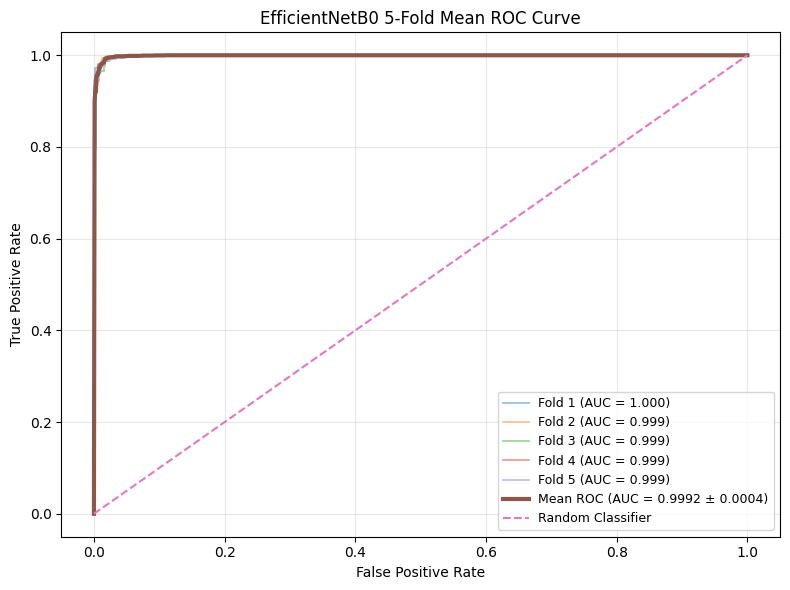

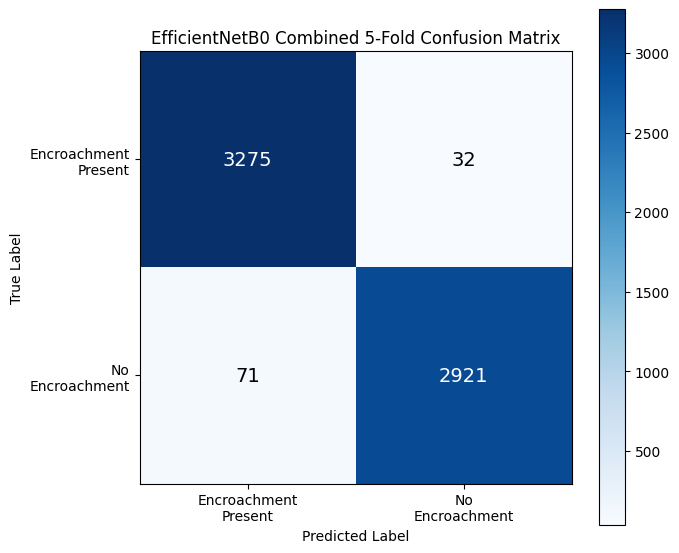


Computational Complexity Table:


,Model,Parameters (M),Trainable Parameters (M),Non-trainable Parameters (M),GFLOPs,Model Size (MB),Inference Time (ms/image),FPS
0,EfficientNetB0,4.050852,0.001281,4.049571,0.800788,16.277572,106.888178,9.355572



FINAL STANDARD PAPER ANALYSIS COMPLETED

TABLES

1. Performance Mean ± SD:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/final_standard_paper_results/tables/EfficientNetB0_performance_mean_std.csv

2. Computational Complexity:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/final_standard_paper_results/tables/EfficientNetB0_computational_complexity.csv

3. Accuracy 95% Confidence Interval:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/final_standard_paper_results/tables/EfficientNetB0_statistical_95CI.csv

FIGURES

4. Five-fold Accuracy Curves:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/final_standard_paper_results/figures/EfficientNetB0_5fold_mean_accuracy_curves.png

5. Five-fold Loss Curves:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/01_EfficientNetB0/final_standard_paper_results/figures/EfficientNetB0_5fold_mean_loss_curves.png

6. Five-fold Mean ROC C

In [3]:
# ============================================================
# EfficientNetB0 FINAL POST-TRAINING ANALYSIS
# Standard 5-Fold Cross-Validation Outputs
# Grad-CAM excluded
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import gc
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import tensorflow as tf
from tensorflow.python.framework.convert_to_constants import (
    convert_variables_to_constants_v2
)

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    confusion_matrix
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
N_FOLDS = 5
IMG_SIZE = 224
BATCH_SIZE = 32
THRESHOLD = 0.50

MODEL_NAME = "EfficientNetB0"

CLASS_NAMES = [
    "Encroachment Present",
    "No Encroachment"
]

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Brishty_ml/"
    "reviewer_final_results"
)

MODEL_OUTPUT_DIR = (
    OUTPUT_DIR /
    "01_EfficientNetB0"
)

MODEL_DIR = (
    MODEL_OUTPUT_DIR /
    "saved_models"
)

METRIC_DIR = (
    MODEL_OUTPUT_DIR /
    "metrics"
)

PREDICTION_DIR = (
    MODEL_OUTPUT_DIR /
    "predictions"
)

HISTORY_DIR = (
    MODEL_OUTPUT_DIR /
    "training_history"
)

TEST_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_test_set.csv"
)

FINAL_DIR = (
    MODEL_OUTPUT_DIR /
    "final_standard_paper_results"
)

TABLE_DIR = (
    FINAL_DIR /
    "tables"
)

FIGURE_DIR = (
    FINAL_DIR /
    "figures"
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 75)
print("EfficientNetB0 FINAL POST-TRAINING ANALYSIS")
print("=" * 75)


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def check_file(file_path):

    file_path = Path(file_path)

    if not file_path.exists():

        raise FileNotFoundError(
            f"Required file was not found:\n{file_path}"
        )


def find_column(
    dataframe,
    possible_names
):

    for column_name in possible_names:

        if column_name in dataframe.columns:

            return column_name

    raise KeyError(
        f"Expected one of these columns: {possible_names}\n"
        f"Available columns: {list(dataframe.columns)}"
    )


def get_model_path(fold_number):

    possible_paths = [
        MODEL_DIR /
        f"EfficientNetB0_fold_{fold_number}.keras",

        MODEL_DIR /
        f"efficientnetb0_fold_{fold_number}.keras",

        MODEL_DIR /
        f"fold_{fold_number}_EfficientNetB0.keras"
    ]

    for model_path in possible_paths:

        if model_path.exists():

            return model_path

    matching_models = list(
        MODEL_DIR.glob(
            f"*fold*{fold_number}*.keras"
        )
    )

    if len(matching_models) == 1:

        return matching_models[0]

    raise FileNotFoundError(
        f"Saved model for Fold {fold_number} "
        f"was not found inside:\n{MODEL_DIR}"
    )


def calculate_model_size_mb(model_path):

    model_path = Path(model_path)

    if model_path.is_file():

        total_bytes = (
            model_path.stat().st_size
        )

    else:

        total_bytes = sum(
            file_path.stat().st_size
            for file_path in model_path.rglob("*")
            if file_path.is_file()
        )

    return (
        total_bytes /
        (1024 ** 2)
    )


def calculate_gflops(
    model,
    image_size=224
):

    concrete_function = tf.function(
        lambda image_batch: model(
            image_batch,
            training=False
        )
    ).get_concrete_function(
        tf.TensorSpec(
            shape=(
                1,
                image_size,
                image_size,
                3
            ),
            dtype=tf.float32
        )
    )

    frozen_function = (
        convert_variables_to_constants_v2(
            concrete_function
        )
    )

    frozen_graph = (
        frozen_function.graph.as_graph_def()
    )

    with tf.Graph().as_default() as graph:

        tf.graph_util.import_graph_def(
            frozen_graph,
            name=""
        )

        profiler_options = (
            tf.compat.v1.profiler
            .ProfileOptionBuilder
            .float_operation()
        )

        profiler_options[
            "output"
        ] = "none"

        profile = (
            tf.compat.v1.profiler.profile(
                graph=graph,
                cmd="op",
                options=profiler_options
            )
        )

    if profile is None:

        return np.nan

    total_flops = float(
        profile.total_float_ops
    )

    return (
        total_flops /
        1e9
    )


def pad_history_arrays(
    history_arrays
):

    maximum_length = max(
        len(history_array)
        for history_array in history_arrays
    )

    padded_matrix = np.full(
        shape=(
            len(history_arrays),
            maximum_length
        ),
        fill_value=np.nan,
        dtype=float
    )

    for index, history_array in enumerate(
        history_arrays
    ):

        padded_matrix[
            index,
            :len(history_array)
        ] = history_array

    return padded_matrix


def get_prediction_columns(
    prediction_df
):

    label_column = find_column(
        prediction_df,
        [
            "label",
            "true_label",
            "y_true"
        ]
    )

    probability_column = find_column(
        prediction_df,
        [
            "predicted_probability_class_1",
            "probability",
            "predicted_probability",
            "class_1_probability"
        ]
    )

    return (
        label_column,
        probability_column
    )


def load_image_for_inference(
    image_path
):

    image_bytes = tf.io.read_file(
        image_path
    )

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([
        None,
        None,
        3
    ])

    image = tf.image.resize(
        image,
        [
            IMG_SIZE,
            IMG_SIZE
        ],
        method="bilinear"
    )

    image = tf.cast(
        image,
        tf.float32
    )

    return image


def create_inference_dataset(
    test_dataframe
):

    image_paths = (
        test_dataframe[
            "image_path"
        ]
        .astype(str)
        .values
    )

    dataset = (
        tf.data.Dataset
        .from_tensor_slices(
            image_paths
        )
    )

    dataset = dataset.map(
        load_image_for_inference,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False
    )

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


def benchmark_inference(
    model,
    dataset,
    number_of_images,
    warmup_batches=5,
    repeats=5
):

    # Warm-up
    for batch_index, image_batch in enumerate(
        dataset
    ):

        _ = model(
            image_batch,
            training=False
        )

        if batch_index + 1 >= warmup_batches:

            break

    elapsed_times = []

    for _ in range(repeats):

        start_time = (
            time.perf_counter()
        )

        for image_batch in dataset:

            _ = model(
                image_batch,
                training=False
            )

        elapsed_time = (
            time.perf_counter() -
            start_time
        )

        elapsed_times.append(
            elapsed_time
        )

    mean_total_seconds = float(
        np.mean(
            elapsed_times
        )
    )

    inference_ms_per_image = (
        mean_total_seconds /
        number_of_images
    ) * 1000

    fps = (
        number_of_images /
        mean_total_seconds
    )

    return (
        inference_ms_per_image,
        fps
    )


# ============================================================
# 3. VERIFY REQUIRED FILES
# ============================================================

check_file(
    TEST_CSV_PATH
)

for fold_number in range(
    1,
    N_FOLDS + 1
):

    check_file(
        METRIC_DIR /
        f"EfficientNetB0_fold_"
        f"{fold_number}_summary.csv"
    )

    check_file(
        PREDICTION_DIR /
        f"EfficientNetB0_fold_"
        f"{fold_number}_validation_predictions.csv"
    )

    check_file(
        HISTORY_DIR /
        f"EfficientNetB0_fold_"
        f"{fold_number}_history.csv"
    )

    get_model_path(
        fold_number
    )

print(
    "All required EfficientNetB0 files were found."
)


# ============================================================
# 4. READ FIVE-FOLD VALIDATION METRICS
# ============================================================

fold_metric_rows = []

for fold_number in range(
    1,
    N_FOLDS + 1
):

    summary_path = (
        METRIC_DIR /
        f"EfficientNetB0_fold_"
        f"{fold_number}_summary.csv"
    )

    summary_df = pd.read_csv(
        summary_path
    )

    validation_rows = summary_df[
        summary_df[
            "dataset"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("validation")
    ]

    if len(validation_rows) != 1:

        raise ValueError(
            f"Fold {fold_number} must contain "
            f"exactly one validation result row."
        )

    current_row = (
        validation_rows
        .iloc[0]
        .to_dict()
    )

    current_row[
        "fold"
    ] = fold_number

    fold_metric_rows.append(
        current_row
    )


fold_metrics_df = pd.DataFrame(
    fold_metric_rows
)

fold_metrics_df = (
    fold_metrics_df
    .sort_values("fold")
    .reset_index(drop=True)
)


# ============================================================
# 5. PERFORMANCE TABLE: MEAN ± STANDARD DEVIATION
# ============================================================

metric_columns = {
    "CV Loss":
        "loss",

    "CV Accuracy (%)":
        "accuracy",

    "Precision (%)":
        "precision",

    "Recall (%)":
        "recall",

    "F1-Score (%)":
        "f1_score",

    "AUC":
        "auc"
}

performance_row = {
    "Model":
        MODEL_NAME
}

for display_name, source_column in (
    metric_columns.items()
):

    if source_column not in (
        fold_metrics_df.columns
    ):

        raise KeyError(
            f"Missing fold metric column: "
            f"{source_column}"
        )

    metric_values = (
        fold_metrics_df[
            source_column
        ]
        .astype(float)
        .values
    )

    if display_name not in [
        "CV Loss",
        "AUC"
    ]:

        metric_values = (
            metric_values *
            100
        )

    mean_value = float(
        np.mean(
            metric_values
        )
    )

    standard_deviation = float(
        np.std(
            metric_values,
            ddof=1
        )
    )

    performance_row[
        display_name
    ] = (
        f"{mean_value:.2f} ± "
        f"{standard_deviation:.2f}"
    )


performance_table_df = pd.DataFrame([
    performance_row
])

performance_table_path = (
    TABLE_DIR /
    "EfficientNetB0_performance_mean_std.csv"
)

performance_table_df.to_csv(
    performance_table_path,
    index=False
)

print(
    "\nPerformance Table (Mean ± SD):"
)

display(
    performance_table_df
)


# ============================================================
# 6. ACCURACY 95% CONFIDENCE INTERVAL
# ============================================================

accuracy_values = (
    fold_metrics_df[
        "accuracy"
    ]
    .astype(float)
    .values *
    100
)

mean_accuracy = float(
    np.mean(
        accuracy_values
    )
)

accuracy_sd = float(
    np.std(
        accuracy_values,
        ddof=1
    )
)

standard_error = (
    accuracy_sd /
    np.sqrt(N_FOLDS)
)

t_critical = stats.t.ppf(
    0.975,
    df=N_FOLDS - 1
)

margin_of_error = (
    t_critical *
    standard_error
)

ci_lower = (
    mean_accuracy -
    margin_of_error
)

ci_upper = (
    mean_accuracy +
    margin_of_error
)


statistical_table_df = pd.DataFrame([
    {
        "Model":
            MODEL_NAME,

        "Mean Accuracy (%)":
            mean_accuracy,

        "Standard Deviation (%)":
            accuracy_sd,

        "95% CI Lower (%)":
            ci_lower,

        "95% CI Upper (%)":
            ci_upper,

        "Paper Format":
            (
                f"{mean_accuracy:.2f}% "
                f"({ci_lower:.2f}%–"
                f"{ci_upper:.2f}%)"
            )
    }
])


statistical_table_path = (
    TABLE_DIR /
    "EfficientNetB0_statistical_95CI.csv"
)

statistical_table_df.to_csv(
    statistical_table_path,
    index=False
)

print(
    "\nAccuracy 95% Confidence Interval:"
)

display(
    statistical_table_df
)


# ============================================================
# 7. READ FIVE-FOLD TRAINING HISTORIES
# ============================================================

train_accuracy_arrays = []
validation_accuracy_arrays = []

train_loss_arrays = []
validation_loss_arrays = []


for fold_number in range(
    1,
    N_FOLDS + 1
):

    history_path = (
        HISTORY_DIR /
        f"EfficientNetB0_fold_"
        f"{fold_number}_history.csv"
    )

    history_df = pd.read_csv(
        history_path
    )

    required_columns = [
        "accuracy",
        "val_accuracy",
        "loss",
        "val_loss"
    ]

    for column_name in required_columns:

        if column_name not in (
            history_df.columns
        ):

            raise KeyError(
                f"Fold {fold_number} history "
                f"is missing column: {column_name}"
            )

    train_accuracy_arrays.append(
        history_df[
            "accuracy"
        ]
        .astype(float)
        .values
    )

    validation_accuracy_arrays.append(
        history_df[
            "val_accuracy"
        ]
        .astype(float)
        .values
    )

    train_loss_arrays.append(
        history_df[
            "loss"
        ]
        .astype(float)
        .values
    )

    validation_loss_arrays.append(
        history_df[
            "val_loss"
        ]
        .astype(float)
        .values
    )


# ============================================================
# 8. FIVE-FOLD ACCURACY CURVES + MEAN CURVES
# ============================================================
# Fold lines:
# alpha = 0.45
# linewidth = 1.3
#
# Mean lines:
# linewidth = 3

train_accuracy_matrix = (
    pad_history_arrays(
        train_accuracy_arrays
    )
)

validation_accuracy_matrix = (
    pad_history_arrays(
        validation_accuracy_arrays
    )
)

mean_train_accuracy = np.nanmean(
    train_accuracy_matrix,
    axis=0
)

mean_validation_accuracy = np.nanmean(
    validation_accuracy_matrix,
    axis=0
)

mean_accuracy_epochs = np.arange(
    1,
    len(mean_train_accuracy) + 1
)


plt.figure(
    figsize=(8, 6)
)


for fold_index in range(
    N_FOLDS
):

    fold_epochs = np.arange(
        1,
        len(
            train_accuracy_arrays[
                fold_index
            ]
        ) + 1
    )

    plt.plot(
        fold_epochs,
        train_accuracy_arrays[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3
    )

    plt.plot(
        fold_epochs,
        validation_accuracy_arrays[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        linestyle="--"
    )


plt.plot(
    mean_accuracy_epochs,
    mean_train_accuracy,
    linewidth=3,
    label="Mean Training Accuracy"
)

plt.plot(
    mean_accuracy_epochs,
    mean_validation_accuracy,
    linewidth=3,
    linestyle="--",
    label="Mean Validation Accuracy"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "EfficientNetB0 5-Fold Accuracy Curves"
)

plt.legend()

plt.grid(
    alpha=0.30
)

plt.tight_layout()


accuracy_curve_path = (
    FIGURE_DIR /
    "EfficientNetB0_5fold_mean_accuracy_curves.png"
)

plt.savefig(
    accuracy_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 9. FIVE-FOLD LOSS CURVES + MEAN CURVES
# ============================================================

train_loss_matrix = (
    pad_history_arrays(
        train_loss_arrays
    )
)

validation_loss_matrix = (
    pad_history_arrays(
        validation_loss_arrays
    )
)

mean_train_loss = np.nanmean(
    train_loss_matrix,
    axis=0
)

mean_validation_loss = np.nanmean(
    validation_loss_matrix,
    axis=0
)

mean_loss_epochs = np.arange(
    1,
    len(mean_train_loss) + 1
)


plt.figure(
    figsize=(8, 6)
)


for fold_index in range(
    N_FOLDS
):

    fold_epochs = np.arange(
        1,
        len(
            train_loss_arrays[
                fold_index
            ]
        ) + 1
    )

    plt.plot(
        fold_epochs,
        train_loss_arrays[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3
    )

    plt.plot(
        fold_epochs,
        validation_loss_arrays[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        linestyle="--"
    )


plt.plot(
    mean_loss_epochs,
    mean_train_loss,
    linewidth=3,
    label="Mean Training Loss"
)

plt.plot(
    mean_loss_epochs,
    mean_validation_loss,
    linewidth=3,
    linestyle="--",
    label="Mean Validation Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "EfficientNetB0 5-Fold Loss Curves"
)

plt.legend()

plt.grid(
    alpha=0.30
)

plt.tight_layout()


loss_curve_path = (
    FIGURE_DIR /
    "EfficientNetB0_5fold_mean_loss_curves.png"
)

plt.savefig(
    loss_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 10. FIVE-FOLD ROC CURVES + MEAN ROC
# ============================================================

mean_fpr = np.linspace(
    0,
    1,
    1000
)

interpolated_tprs = []
fold_auc_values = []


plt.figure(
    figsize=(8, 6)
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    prediction_path = (
        PREDICTION_DIR /
        f"EfficientNetB0_fold_"
        f"{fold_number}_validation_predictions.csv"
    )

    prediction_df = pd.read_csv(
        prediction_path
    )

    (
        label_column,
        probability_column
    ) = get_prediction_columns(
        prediction_df
    )

    true_labels = (
        prediction_df[
            label_column
        ]
        .astype(int)
        .values
    )

    probabilities = (
        prediction_df[
            probability_column
        ]
        .astype(float)
        .values
    )

    fold_fpr, fold_tpr, _ = roc_curve(
        true_labels,
        probabilities
    )

    fold_auc = roc_auc_score(
        true_labels,
        probabilities
    )

    fold_auc_values.append(
        fold_auc
    )

    interpolated_tpr = np.interp(
        mean_fpr,
        fold_fpr,
        fold_tpr
    )

    interpolated_tpr[0] = 0.0

    interpolated_tprs.append(
        interpolated_tpr
    )

    plt.plot(
        fold_fpr,
        fold_tpr,
        alpha=0.45,
        linewidth=1.3,
        label=(
            f"Fold {fold_number} "
            f"(AUC = {fold_auc:.3f})"
        )
    )


mean_tpr = np.mean(
    interpolated_tprs,
    axis=0
)

mean_tpr[0] = 0.0
mean_tpr[-1] = 1.0

mean_auc = float(
    np.mean(
        fold_auc_values
    )
)

auc_sd = float(
    np.std(
        fold_auc_values,
        ddof=1
    )
)


plt.plot(
    mean_fpr,
    mean_tpr,
    linewidth=3,
    label=(
        f"Mean ROC "
        f"(AUC = {mean_auc:.4f} "
        f"± {auc_sd:.4f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "EfficientNetB0 5-Fold Mean ROC Curve"
)

plt.legend(
    loc="lower right",
    fontsize=9
)

plt.grid(
    alpha=0.30
)

plt.tight_layout()


roc_curve_path = (
    FIGURE_DIR /
    "EfficientNetB0_5fold_mean_ROC_curve.png"
)

plt.savefig(
    roc_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 11. COMBINED FIVE-FOLD CONFUSION MATRIX
# ============================================================

combined_cm = np.zeros(
    shape=(2, 2),
    dtype=int
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    prediction_path = (
        PREDICTION_DIR /
        f"EfficientNetB0_fold_"
        f"{fold_number}_validation_predictions.csv"
    )

    prediction_df = pd.read_csv(
        prediction_path
    )

    (
        label_column,
        probability_column
    ) = get_prediction_columns(
        prediction_df
    )

    true_labels = (
        prediction_df[
            label_column
        ]
        .astype(int)
        .values
    )

    possible_prediction_columns = [
        "predicted_label",
        "prediction",
        "y_pred"
    ]

    prediction_column = None

    for column_name in (
        possible_prediction_columns
    ):

        if column_name in (
            prediction_df.columns
        ):

            prediction_column = (
                column_name
            )

            break

    if prediction_column is not None:

        predicted_labels = (
            prediction_df[
                prediction_column
            ]
            .astype(int)
            .values
        )

    else:

        probabilities = (
            prediction_df[
                probability_column
            ]
            .astype(float)
            .values
        )

        predicted_labels = (
            probabilities >=
            THRESHOLD
        ).astype(int)

    fold_cm = confusion_matrix(
        true_labels,
        predicted_labels,
        labels=[0, 1]
    )

    combined_cm += fold_cm


plt.figure(
    figsize=(7, 6)
)

plt.imshow(
    combined_cm,
    interpolation="nearest",
    cmap="Blues"
)

plt.colorbar()


display_class_names = [
    "Encroachment\nPresent",
    "No\nEncroachment"
]

tick_positions = np.arange(
    len(display_class_names)
)

plt.xticks(
    tick_positions,
    display_class_names
)

plt.yticks(
    tick_positions,
    display_class_names
)


cell_threshold = (
    combined_cm.max() /
    2
)


for row_index in range(2):

    for column_index in range(2):

        cell_value = combined_cm[
            row_index,
            column_index
        ]

        plt.text(
            column_index,
            row_index,
            str(cell_value),
            horizontalalignment="center",
            verticalalignment="center",
            fontsize=14,
            color=(
                "white"
                if cell_value >
                cell_threshold
                else "black"
            )
        )


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "EfficientNetB0 Combined 5-Fold Confusion Matrix"
)

plt.tight_layout()


combined_cm_path = (
    FIGURE_DIR /
    "EfficientNetB0_combined_5fold_confusion_matrix.png"
)

plt.savefig(
    combined_cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 12. COMPUTATIONAL COMPLEXITY
# ============================================================
# পাঁচ fold-এর architecture একই।
# তাই একটি saved fold model যথেষ্ট।

complexity_model_path = (
    get_model_path(
        fold_number=1
    )
)

tf.keras.backend.clear_session()
gc.collect()


complexity_model = (
    tf.keras.models.load_model(
        complexity_model_path,
        compile=False
    )
)


total_parameters = int(
    complexity_model.count_params()
)

trainable_parameters = int(
    np.sum([
        tf.keras.backend.count_params(
            weight
        )
        for weight in
        complexity_model.trainable_weights
    ])
)

non_trainable_parameters = (
    total_parameters -
    trainable_parameters
)


model_size_mb = (
    calculate_model_size_mb(
        complexity_model_path
    )
)


try:

    gflops = calculate_gflops(
        complexity_model,
        image_size=IMG_SIZE
    )

except Exception as error:

    print(
        "\nGFLOPs calculation warning:",
        error
    )

    gflops = np.nan


# ============================================================
# 13. INFERENCE TIME AND FPS
# ============================================================

test_df = pd.read_csv(
    TEST_CSV_PATH
)


if "image_path" not in (
    test_df.columns
):

    raise KeyError(
        "fixed_test_set.csv must contain "
        "an image_path column."
    )


missing_images = test_df[
    ~test_df[
        "image_path"
    ]
    .astype(str)
    .apply(
        lambda image_path:
            Path(image_path).exists()
    )
]


if len(missing_images) > 0:

    raise FileNotFoundError(
        f"{len(missing_images)} test images "
        f"could not be found."
    )


test_dataset = (
    create_inference_dataset(
        test_df
    )
)


(
    inference_ms_per_image,
    fps
) = benchmark_inference(
    model=complexity_model,
    dataset=test_dataset,
    number_of_images=len(
        test_df
    ),
    warmup_batches=5,
    repeats=5
)


complexity_table_df = pd.DataFrame([
    {
        "Model":
            MODEL_NAME,

        "Parameters (M)":
            total_parameters /
            1e6,

        "Trainable Parameters (M)":
            trainable_parameters /
            1e6,

        "Non-trainable Parameters (M)":
            non_trainable_parameters /
            1e6,

        "GFLOPs":
            gflops,

        "Model Size (MB)":
            model_size_mb,

        "Inference Time (ms/image)":
            inference_ms_per_image,

        "FPS":
            fps
    }
])


complexity_table_path = (
    TABLE_DIR /
    "EfficientNetB0_computational_complexity.csv"
)

complexity_table_df.to_csv(
    complexity_table_path,
    index=False
)


print(
    "\nComputational Complexity Table:"
)

display(
    complexity_table_df
)


# ============================================================
# 14. FINAL OUTPUT CHECKLIST
# ============================================================

print(
    "\n" + "=" * 75
)

print(
    "FINAL STANDARD PAPER ANALYSIS COMPLETED"
)

print(
    "=" * 75
)


print(
    "\nTABLES"
)

print(
    "\n1. Performance Mean ± SD:"
)

print(
    performance_table_path
)


print(
    "\n2. Computational Complexity:"
)

print(
    complexity_table_path
)


print(
    "\n3. Accuracy 95% Confidence Interval:"
)

print(
    statistical_table_path
)


print(
    "\nFIGURES"
)

print(
    "\n4. Five-fold Accuracy Curves:"
)

print(
    accuracy_curve_path
)


print(
    "\n5. Five-fold Loss Curves:"
)

print(
    loss_curve_path
)


print(
    "\n6. Five-fold Mean ROC Curve:"
)

print(
    roc_curve_path
)


print(
    "\n7. Combined Five-fold Confusion Matrix:"
)

print(
    combined_cm_path
)


print(
    "\nAll outputs were saved inside:"
)

print(
    FINAL_DIR
)


print(
    "\nGrad-CAM and Grad-CAM++ will be generated "
    "later only for the final best-performing model."
)


print(
    "\nMcNemar Test will be generated after all "
    "comparison models have produced predictions "
    "on the same independent test set."
)